<div style="text-align:center"><img src="https://raw.githubusercontent.com/kauacarv1/GS-CitizenTech/main/assets/banner_fiap.png" /></div>

# Sentinela: previsão de dengue nos municípios de São Paulo com clima, Rt e limiares epidêmicos

**Integrantes:**<br>
Kauã Carvalho de Oliveira · RM 566371<br>
João Vitor Piccolo · RM 565127<br>
Gabrielle Calazans · RM 564460<br>
Jéssica Domingues · RM 562973<br>
Leonardo Pereira · RM 561349

**Curso:** Engenharia de Software (ESPY2), FIAP · **Data:** novembro de 2026

## 1. Introdução

A dengue é a arbovirose urbana de maior impacto no Brasil. O vírus é transmitido pelo mosquito *Aedes aegypti*, cujo ciclo de vida depende da temperatura e da umidade. Em períodos quentes e úmidos o mosquito se desenvolve mais rápido, o vírus incuba em menos tempo dentro dele e a transmissão aumenta. Por isso a doença é muito sazonal: no Sudeste, os picos acontecem entre fevereiro e maio.

Este projeto monta um sistema de previsão e alerta de dengue para o estado de São Paulo. Ele combina as notificações de casos, o clima e dois indicadores calculados para cada município: o número reprodutivo efetivo (Rt) e os limiares epidêmicos. Todos os dados vêm direto das fontes primárias, sem APIs intermediárias.

### Objetivos

1. Montar uma base semanal dos 645 municípios do estado de São Paulo, de 2014 até as semanas mais recentes de 2026, com dados baixados diretamente do SINAN, do Copernicus (ERA5-Land) e do IBGE.
2. Estimar o Rt e os limiares pré-epidêmico, pós-epidêmico e epidêmico de cada município.
3. Treinar modelos de aprendizado de máquina para duas tarefas:
   - regressão: prever a incidência de dengue 1 e 4 semanas à frente;
   - classificação: prever se a incidência vai passar do limiar epidêmico do município.
4. Avaliar os modelos com validação temporal em janelas móveis, retreinando a cada ano, tanto nas previsões pontuais quanto nas faixas de incerteza, e comparar os resultados com previsões de referência (*baselines*).

### Perguntas de pesquisa

1. Dá para prever, com 1 e 4 semanas de antecedência, quantos casos de dengue cada município de SP vai ter?
2. Dá para antecipar quais municípios vão entrar em situação epidêmica?
3. Quanto o clima (temperatura e umidade) e a situação dos municípios vizinhos ajudam nessas previsões?
4. Que ações de vigilância e controle essas previsões ajudam a orientar, e com quais riscos?

### Variáveis-alvo

| Tarefa | Variável-alvo | Tipo | Definição |
|---|---|---|---|
| Regressão | `y`: incidência na semana `T + h` | contínua (casos por 100 mil hab.) | notificações de dengue de residentes do município, por semana de início dos sintomas, ÷ população × 100 mil |
| Classificação | `evento`: semana epidêmica em `T + h` | binária (0/1) | 1 se a incidência passar do limiar epidêmico do município (seção 8) e houver mais de 10 casos; 0 nos outros casos |

`T` é a semana em que a previsão é feita, e `h` (1 ou 4 semanas) é o horizonte.

<small>*Nota*: previsões de doenças devem ser usadas junto com a vigilância epidemiológica, o monitoramento de vetores e a avaliação de especialistas.</small>

## 2. Dados

### 2.1 Fontes

| Fonte | Conteúdo | Forma de acesso |
|---|---|---|
| SINAN (Ministério da Saúde) | notificações individuais de dengue, um arquivo nacional por ano (`DENGBRaa`) | Portal de Dados Abertos do SUS (arquivos Parquet/CSV) |
| ERA5-Land (Copernicus/ECMWF) | reanálise climática com resolução de 0,1° (~9 km): temperatura e ponto de orvalho a 2 m, em agregados diários | Google Earth Engine, coleção `ECMWF/ERA5_LAND/DAILY_AGGR` |
| IBGE (SIDRA) | estimativas de população (tabela 6579) e Censo 2022 (tabela 4709) | API SIDRA |
| IBGE (malhas e localidades) | polígonos e nomes dos municípios | APIs de serviços de dados |

### 2.2 Variáveis construídas (município × semana epidemiológica)

| Variável | Descrição |
|---|---|
| `casos` | notificações de dengue por semana de início dos sintomas, no município de residência |
| `atraso` | semanas entre o início dos sintomas e a digitação no SINAN |
| `pop` | população residente |
| `incidencia` | casos por 100 mil habitantes |
| `temp_min`, `temp_med`, `temp_max` | médias semanais das temperaturas diárias mínima, média e máxima (°C) |
| `umid_min`, `umid_med`, `umid_max` | umidade relativa do ar (%) |
| `Rt`, `p1` | número reprodutivo efetivo e probabilidade de Rt > 1 |
| `limiar_pre`, `limiar_pos`, `limiar_epidemico` | limiares de incidência do município |

### 2.3 Como executar

O notebook foi feito para o Google Colab, mas também roda no Jupyter local.

Para o clima é preciso ter acesso ao [Google Earth Engine](https://code.earthengine.google.com/register), que é gratuito para uso não comercial e acadêmico. Use a mesma conta Google do Colab. O cadastro cria um projeto do Google Cloud; coloque o ID desse projeto em `GEE_PROJETO`, no começo da célula de clima (seção 4.5). Na primeira execução, o Colab pede autorização para acessar o Earth Engine.

As exportações do Earth Engine levam de alguns minutos a cerca de uma hora, e o andamento aparece em <https://code.earthengine.google.com/tasks>. Tudo fica em cache: um arquivo que já existe não é baixado nem exportado de novo, então a execução pode ser interrompida e retomada.

Para economizar espaço, cada arquivo anual do SINAN vai para o disco temporário do Colab, onde é filtrado para SP, agregado e apagado. No Google Drive ficam só os dados processados (dezenas de MB) e as tabelas diárias de clima exportadas pelo Earth Engine (~200 MB, que podem ser apagadas depois). As pastas são criadas automaticamente.

A base vai até a última semana com notificações digitadas no SINAN. O arquivo do SINAN do ano corrente é baixado de novo quando a cópia salva tem mais de 7 dias, e o mesmo vale para o clima do ano corrente. Assim, rodar o notebook de novo a cada semana atualiza a base e as previsões. Os modelos são retreinados sempre que a data de corte dos dados muda.

In [12]:
# Dependências (o Colab já traz a maioria)
%pip install -q earthengine-api shapely pyarrow scipy scikit-learn requests

## 3. Configuração

In [13]:
import json, os, shutil, sys, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon as MplPolygon

from scipy import stats
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, precision_score,
                             recall_score, f1_score, average_precision_score, precision_recall_curve)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

warnings.simplefilter("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", category=RuntimeWarning, message="invalid value")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

In [14]:
# ---------------- Parâmetros do estudo ----------------
UF_CODIGO, UF_SIGLA = "35", "SP"
ANO_INICIO, ANO_FIM = 2014, 2026
ANO_ATUAL = pd.Timestamp.now().year
# inclui o arquivo do ano seguinte (sintomas em dezembro, notificação em janeiro), se ele já existir
ANOS_SINAN = range(ANO_INICIO, min(ANO_FIM + 1, ANO_ATUAL) + 1)
ANOS_CLIMA = range(ANO_INICIO - 1, min(ANO_FIM, ANO_ATUAL) + 1)  # um ano antes, para as defasagens climáticas
SEMANAS_INCOMPLETAS = 8      # semanas mais recentes ainda recebem casos atrasados: ficam fora do treino e da avaliação

COL_MUNICIPIO = "ID_MN_RESI"   # município de residência
MAX_ATRASO = 26                # atrasos maiores são agrupados nesta classe (semanas)

TREINO_ATE = pd.Timestamp("2021-12-31")   # limiares epidêmicos e projeção sazonal usam dados até 2021
                                          # (os modelos de previsão usam janelas móveis: seção 9.4)
HORIZONTES = [1, 4]                        # semanas à frente
RETREINAR_MODELOS = False                  # False: reaproveita os resultados dos modelos salvos no Drive
                                           # (mude para True se alterar variáveis, modelos ou período)
RANDOM_STATE = 42

# Pasta de dados: no Colab, o Google Drive guarda o cache entre sessões
NO_COLAB = "google.colab" in sys.modules
USAR_GOOGLE_DRIVE = True
if NO_COLAB and USAR_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DIR_DADOS = Path("/content/drive/MyDrive/dengue_sp/dados")
    DIR_TEMP = Path("/content/temp_sinan")     # disco local do Colab: arquivos nacionais grandes e temporários
else:
    DIR_DADOS = Path("dados")
    DIR_TEMP = DIR_DADOS / "bruto"
DIR_BRUTO = DIR_DADOS / "bruto"
for d in (DIR_BRUTO / "ibge", DIR_BRUTO / "era5", DIR_DADOS / "sinan", DIR_TEMP):
    d.mkdir(parents=True, exist_ok=True)   # as pastas são criadas automaticamente
print("Dados em:", DIR_DADOS.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dados em: /content/drive/MyDrive/dengue_sp/dados


### 3.1 Funções auxiliares

A semana epidemiológica (SE) começa no domingo, e a SE 1 é a primeira semana do ano com pelo menos quatro dias em janeiro. Como alguns anos têm 53 semanas, o tempo é indexado pela data do domingo que abre cada semana, e o par (ano, SE) é calculado a partir dela.

In [15]:
def inicio_semana(datas):
    """Domingo que inicia a semana epidemiológica de cada data."""
    d = pd.to_datetime(pd.Series(datas)).dt.normalize()
    return d - pd.to_timedelta((d.dt.weekday + 1) % 7, unit="D")


def ano_se(semanas):
    """(ano epidemiológico, SE) a partir do domingo de início: a quarta-feira define o ano."""
    qua = pd.to_datetime(pd.Series(semanas)) + pd.Timedelta(days=3)
    return qua.dt.year.to_numpy(), ((qua.dt.dayofyear - 1) // 7 + 1).to_numpy()


def para_data(s):
    """Converte datas nos formatos AAAA-MM-DD, AAAAMMDD ou DD/MM/AAAA, tolerando valores inválidos."""
    s = pd.Series(s, dtype="object").astype(str).str.strip().str[:10]
    d = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    for fmt, padrao in (("%Y%m%d", r"\d{8}"), ("%d/%m/%Y", r"\d{2}/\d{2}/\d{4}")):
        m = d.isna() & s.str.fullmatch(padrao)
        if m.any():
            d[m] = pd.to_datetime(s[m], format=fmt, errors="coerce")
    return d


def baixar(url, destino, params=None, tentativas=3):
    """Baixa um arquivo em blocos, com novas tentativas; se ele já existe, não baixa de novo."""
    import time
    destino = Path(destino)
    if destino.exists():
        return destino
    tmp = destino.with_name(destino.name + ".part")
    for tentativa in range(1, tentativas + 1):
        try:
            print(f"Baixando {destino.name} ...", end=" ", flush=True)
            with requests.get(url, params=params, stream=True, timeout=(30, 300)) as r:
                r.raise_for_status()
                with open(tmp, "wb") as f:
                    for bloco in r.iter_content(chunk_size=1 << 20):
                        f.write(bloco)
            tmp.replace(destino)
            print(f"{destino.stat().st_size / 1e6:.1f} MB")
            return destino
        except requests.HTTPError:
            print("não encontrado")
            raise
        except requests.RequestException as e:
            print(f"falhou (tentativa {tentativa}/{tentativas}): {type(e).__name__}")
            if tentativa == tentativas:
                raise
            time.sleep(10 * tentativa)


_t = inicio_semana(["2024-01-01", "2021-01-01"])
print("Conferência:", [(str(d.date()), int(a), int(s)) for d, a, s in zip(_t, *ano_se(_t))],
      "-> esperado SE 1/2024 e SE 53/2020")

Conferência: [('2023-12-31', 2024, 1), ('2020-12-27', 2020, 53)] -> esperado SE 1/2024 e SE 53/2020


## 4. Extração dos dados

### 4.1 Arquivos do IBGE

São quatro arquivos pequenos: a lista de municípios, a malha territorial (polígonos) e duas tabelas de população do SIDRA.

O servidor do IBGE às vezes fica instável ou não responde a acessos de fora do Brasil, como os do Colab. Se o download falhar mesmo depois das novas tentativas, a célula mostra os links. Nesse caso, abra cada link no navegador do seu computador, salve o arquivo com o nome indicado na pasta indicada do Google Drive e rode a célula de novo.

In [16]:
DIR_IBGE = DIR_BRUTO / "ibge"
# anos com estimativa na tabela 6579 (não há 2022 e 2023; 2022 vem do Censo e 2023 é interpolado)
ANOS_ESTIMATIVAS = ",".join(str(a) for a in range(ANO_INICIO - 1, min(ANO_FIM, 2025) + 1) if a not in (2022, 2023))
ARQUIVOS_IBGE = {
    f"municipios_{UF_SIGLA}.json": (f"https://servicodados.ibge.gov.br/api/v1/localidades/estados/{UF_CODIGO}/municipios", None),
    f"malha_{UF_SIGLA}.geojson": (f"https://servicodados.ibge.gov.br/api/v3/malhas/estados/{UF_CODIGO}",
                                  {"formato": "application/vnd.geo+json", "intrarregiao": "municipio", "qualidade": "intermediaria"}),
    f"pop_estimativas_{UF_SIGLA}.json": (f"https://apisidra.ibge.gov.br/values/t/6579/n6/in%20n3%20{UF_CODIGO}/v/9324/p/{ANOS_ESTIMATIVAS}", {"formato": "json"}),
    f"pop_censo2022_{UF_SIGLA}.json": (f"https://apisidra.ibge.gov.br/values/t/4709/n6/in%20n3%20{UF_CODIGO}/v/93/p/2022", {"formato": "json"}),
}

faltando = []
for nome, (url, params) in ARQUIVOS_IBGE.items():
    try:
        baixar(url, DIR_IBGE / nome, params=params)
    except requests.RequestException:
        faltando.append((nome, requests.Request("GET", url, params=params).prepare().url))

if faltando:
    pasta = "MyDrive/dengue_sp/dados/bruto/ibge" if (NO_COLAB and USAR_GOOGLE_DRIVE) else str(DIR_IBGE.resolve())
    print("\n" + "=" * 90)
    print("O IBGE não respondeu. Abra cada link abaixo no navegador do seu computador, salve a página")
    print(f"(Ctrl+S) com o nome indicado e coloque o arquivo na pasta: {pasta}\n")
    for nome, link in faltando:
        print(f"  nome do arquivo: {nome}\n  link: {link}\n")
    print("Depois rode esta célula de novo.")
    print("=" * 90)
    raise RuntimeError(f"{len(faltando)} arquivo(s) do IBGE pendente(s) — veja as instruções acima.")
print("Arquivos do IBGE prontos.")

Arquivos do IBGE prontos.


### 4.2 Municípios e malha territorial

In [17]:
from shapely.geometry import shape

arq_mun, arq_malha = DIR_IBGE / f"municipios_{UF_SIGLA}.json", DIR_IBGE / f"malha_{UF_SIGLA}.geojson"
geojson = json.loads(arq_malha.read_text(encoding="utf-8-sig"))
geoms = {int(f["properties"]["codarea"]): shape(f["geometry"]) for f in geojson["features"]}
nomes = {int(m["id"]): m["nome"] for m in json.loads(arq_mun.read_text(encoding="utf-8-sig"))}

muns = pd.DataFrame({"geocodigo": sorted(geoms)})
muns["geocod6"] = muns.geocodigo.astype(str).str[:6]      # o SINAN usa o código de 6 dígitos
muns["nome"] = muns.geocodigo.map(nomes)
M = len(muns)
print(f"{M} municípios")
muns.head()

645 municípios


,geocodigo,geocod6,nome
0,3500105,350010,Adamantina
1,3500204,350020,Adolfo
2,3500303,350030,Aguaí
3,3500402,350040,Águas da Prata
4,3500501,350050,Águas de Lindóia


### 4.3 População (IBGE/SIDRA)

A tabela 6579 tem as estimativas anuais, e a 4709 tem o Censo 2022. Os anos sem dado são interpolados linearmente, município a município.

In [18]:
def ler_sidra(arquivo):
    dados = json.loads(Path(arquivo).read_text(encoding="utf-8-sig"))
    cab, linhas = dados[0], pd.DataFrame(dados[1:])
    col_mun = next(k for k, v in cab.items() if v.startswith("Município") and v.endswith("(Código)"))
    col_ano = next(k for k, v in cab.items() if v.startswith("Ano") and v.endswith("(Código)"))
    return pd.DataFrame({"geocodigo": linhas[col_mun].astype(int), "ano": linhas[col_ano].astype(int),
                         "pop": pd.to_numeric(linhas["V"], errors="coerce")}).dropna()


pop_long = pd.concat([ler_sidra(DIR_IBGE / f"pop_estimativas_{UF_SIGLA}.json"),
                      ler_sidra(DIR_IBGE / f"pop_censo2022_{UF_SIGLA}.json")])
pop_long = pop_long.drop_duplicates(["geocodigo", "ano"], keep="last")
pop_anual = (pop_long.pivot(index="ano", columns="geocodigo", values="pop")
                     .reindex(index=range(ANO_INICIO - 1, ANO_FIM + 2), columns=muns.geocodigo)
                     .interpolate(limit_direction="both"))
print("População do estado (milhões):")
print((pop_anual.loc[ANO_INICIO:ANO_FIM].sum(axis=1) / 1e6).round(2).to_string())

População do estado (milhões):
ano
2014    44.04
2015    44.40
2016    44.75
2017    45.09
2018    45.54
2019    45.92
2020    46.29
2021    46.65
2022    44.41
2023    45.19
2024    45.97
2025    46.08
2026    46.08


### 4.4 Notificações de dengue (SINAN)

Cada arquivo anual traz todas as notificações do país. O código lê só as colunas necessárias, em blocos, fica com os residentes em SP e agrega por município, semana de início dos sintomas e atraso de digitação.

| Coluna | Uso |
|---|---|
| `DT_SIN_PRI` | data de início dos sintomas (se estiver vazia, usa `DT_NOTIFIC`) |
| `DT_NOTIFIC` | data da notificação |
| `DT_DIGITA` | data de digitação no sistema, usada para calcular o atraso |
| `ID_MN_RESI` | município de residência (6 dígitos) |

Com o atraso guardado, dá para saber quantos casos de qualquer semana passada já estavam registrados naquele momento. A modelagem usa isso para que as variáveis mostrem só o que se sabia na data da previsão.

In [19]:
URL_SINAN = "https://s3.sa-east-1.amazonaws.com/ckan.saude.gov.br/SINAN/Dengue/{fmt}/DENGBR{aa}.{fmt}.zip"
COLS_SINAN = ["DT_SIN_PRI", "DT_NOTIFIC", "DT_DIGITA", "ID_MN_RESI"]
TAM_BLOCO = 500_000


def agrega_bloco(df):
    """Mantém residentes na UF e conta notificações por (município, semana dos sintomas, atraso)."""
    df = df.rename(columns=lambda c: c.strip().upper())
    mun = df[COL_MUNICIPIO].astype(str).str.replace(r"\.0$", "", regex=True).str.strip().str[:6]
    manter = mun.str.startswith(UF_CODIGO)
    df, mun = df[manter], mun[manter]
    if df.empty:
        return None
    dt_sin = para_data(df["DT_SIN_PRI"]) if "DT_SIN_PRI" in df else pd.Series(pd.NaT, index=df.index)
    if "DT_NOTIFIC" in df:
        dt_sin = dt_sin.fillna(para_data(df["DT_NOTIFIC"]))
    semana = inicio_semana(dt_sin).set_axis(df.index)
    if "DT_DIGITA" in df:
        atraso = ((inicio_semana(para_data(df["DT_DIGITA"])).set_axis(df.index) - semana).dt.days // 7)
        atraso = atraso.fillna(0).clip(0, MAX_ATRASO)
    else:
        atraso = pd.Series(0, index=df.index)
    out = pd.DataFrame({"geocod6": mun.values, "semana": semana.values, "atraso": atraso.astype(int).values})
    return out.dropna(subset=["semana"]).groupby(["geocod6", "semana", "atraso"]).size().rename("n").reset_index()


def blocos_parquet(arq_zip, pasta_tmp):
    import pyarrow.parquet as pq
    with zipfile.ZipFile(arq_zip) as z:
        membros = [m for m in z.namelist() if m.lower().endswith(".parquet")]
        z.extractall(pasta_tmp, members=membros)
    for m in membros:
        pf = pq.ParquetFile(Path(pasta_tmp) / m)
        nomes_col = {c.upper(): c for c in pf.schema_arrow.names}
        cols = [nomes_col[c] for c in COLS_SINAN if c in nomes_col]
        for lote in pf.iter_batches(batch_size=TAM_BLOCO, columns=cols):
            yield lote.to_pandas().astype(str).replace({"None": None, "nan": None, "NaT": None})


def blocos_csv(arq_zip):
    with zipfile.ZipFile(arq_zip) as z:
        membro = next(m for m in z.namelist() if m.lower().endswith(".csv"))
        with z.open(membro) as f:
            cabecalho = f.readline().decode("latin-1")
        sep = max([",", ";", "|", "\t"], key=cabecalho.count)
        with z.open(membro) as f:
            yield from pd.read_csv(f, sep=sep, dtype=str, encoding="latin-1", chunksize=TAM_BLOCO,
                                   usecols=lambda c: c.strip().upper() in COLS_SINAN)


def processar_sinan(ano):
    aa = f"{ano % 100:02d}"
    destino = DIR_DADOS / "sinan" / f"DENG{aa}_{UF_SIGLA}.parquet"
    recente = destino.exists() and (time.time() - destino.stat().st_mtime) < 7 * 86400
    if destino.exists() and (ano < ANO_ATUAL or recente):
        return destino              # anos fechados não mudam; o ano corrente é atualizado a cada 7 dias
    for fmt in ("parquet", "csv"):          # Parquet é menor; CSV é a alternativa
        arq = DIR_TEMP / f"DENGBR{aa}.{fmt}.zip"
        try:
            baixar(URL_SINAN.format(fmt=fmt, aa=aa), arq)
            break
        except requests.RequestException as e:
            print(f"{arq.name} indisponível ({e}); tentando outro formato")
    else:
        if ano >= ANO_ATUAL - 1:    # arquivo do ano corrente ainda não publicado
            print(f"SINAN {ano} ainda não está disponível; seguindo sem ele")
            return destino if destino.exists() else None
        raise RuntimeError(f"SINAN {ano} não encontrado")
    pasta_tmp = DIR_TEMP / f"tmp_{aa}"
    blocos = blocos_parquet(arq, pasta_tmp) if fmt == "parquet" else blocos_csv(arq)
    partes = [p for p in map(agrega_bloco, blocos) if p is not None]
    agreg = pd.concat(partes).groupby(["geocod6", "semana", "atraso"])["n"].sum().reset_index()
    agreg.to_parquet(destino, index=False)
    shutil.rmtree(pasta_tmp, ignore_errors=True)
    arq.unlink(missing_ok=True)              # apaga o arquivo nacional
    print(f"SINAN {ano}: {agreg.n.sum():,} notificações de residentes em {UF_SIGLA}")
    return destino


import time
sinan = pd.concat([pd.read_parquet(p) for p in map(processar_sinan, ANOS_SINAN) if p is not None])
sinan["semana"] = pd.to_datetime(sinan["semana"])
sinan = sinan.groupby(["geocod6", "semana", "atraso"])["n"].sum().reset_index()
print(f"\nTotal: {sinan.n.sum():,} notificações | {sinan.geocod6.nunique()} municípios com casos")


Total: 6,879,160 notificações | 647 municípios com casos


### 4.5 Clima (ERA5-Land, via Google Earth Engine)

O clima vem do ERA5-Land, a reanálise do Copernicus/ECMWF com resolução de 0,1° (~9 km). O acesso é feito pelo Google Earth Engine, que já oferece o ERA5-Land com agregados diários (`ECMWF/ERA5_LAND/DAILY_AGGR`) e não tem a fila de processamento do Climate Data Store do Copernicus.

| Variável do ERA5-Land | Variável resultante |
|---|---|
| temperatura a 2 m, mínima diária | `temp_min` |
| temperatura a 2 m, média diária | `temp_med` |
| temperatura a 2 m, máxima diária | `temp_max` |
| ponto de orvalho a 2 m, média diária | umidade relativa |

Para cada ano, o Earth Engine calcula a média diária de cada município, ponderada pela fração de cada pixel que cai dentro do polígono (assim, municípios menores que um pixel também recebem valor), e exporta uma tabela CSV para o Google Drive. Há uma exportação por ano, de 2013 até o ano atual, e elas rodam em paralelo nos servidores do Google. Depois da primeira execução, só o ano corrente é exportado de novo.

A umidade relativa é calculada pela fórmula de Magnus, $UR = 100\, e_s(T_d)/e_s(T)$, com $e_s(T) = 6{,}112 \exp\!\left(\frac{17{,}62\,T}{243{,}12+T}\right)$. A umidade média usa a temperatura média, a máxima usa a temperatura mínima e a mínima usa a máxima. É uma aproximação que funciona porque o ponto de orvalho varia pouco ao longo do dia. Depois, os valores diários viram médias semanais.

<small>Os dias do agregado diário seguem o horário UTC, 3 horas à frente de Brasília. O efeito disso nas médias semanais é desprezível.</small>

In [11]:
import time
import ee
from shapely.geometry import mapping

GEE_PROJETO = "COLE-AQUI-O-ID-DO-PROJETO"   # ID do projeto do Google Cloud registrado no Earth Engine
COLECAO_GEE = "ECMWF/ERA5_LAND/DAILY_AGGR"
BANDAS_GEE = {"temperature_2m_min": "tmin", "temperature_2m": "tmed",
              "temperature_2m_max": "tmax", "dewpoint_temperature_2m": "tdmed"}
PASTA_DRIVE_GEE = "dengue_sp_gee"            # pasta criada pelo Earth Engine na raiz do Google Drive
DIR_GEE = Path("/content/drive/MyDrive") / PASTA_DRIVE_GEE if NO_COLAB else DIR_DADOS / "gee"


def nome_exportacao(ano):
    return f"clima_{UF_SIGLA}_era5land_{ano}"


def municipios_ee():
    """Polígonos dos municípios como FeatureCollection do Earth Engine (simplificados ~500 m, bem menor que um pixel)."""
    feats = [ee.Feature(ee.Geometry(mapping(geoms[g].simplify(0.005, preserve_topology=True))), {"geocodigo": int(g)})
             for g in muns.geocodigo]
    return ee.FeatureCollection(feats)


def exportar_ano(ano, fc):
    """Média diária de cada município (média ponderada pela área de cada pixel) -> CSV no Google Drive."""
    col = (ee.ImageCollection(COLECAO_GEE).filterDate(f"{ano}-01-01", f"{ano + 1}-01-01").select(list(BANDAS_GEE)))

    def por_dia(img):
        data = img.date().format("YYYY-MM-dd")
        return img.reduceRegions(collection=fc, reducer=ee.Reducer.mean(), scale=11132).map(lambda f: f.set("data", data))

    tarefa = ee.batch.Export.table.toDrive(
        collection=col.map(por_dia).flatten(), description=nome_exportacao(ano), folder=PASTA_DRIVE_GEE,
        fileNamePrefix=nome_exportacao(ano), fileFormat="CSV", selectors=["geocodigo", "data"] + list(BANDAS_GEE))
    tarefa.start()
    return tarefa


def umidade_relativa(t, td):
    es = lambda x: 6.112 * np.exp(17.62 * x / (243.12 + x))
    return np.clip(100 * es(td) / es(t), 0, 100)


arq_clima = DIR_DADOS / f"clima_{UF_SIGLA}_semanal.parquet"
clima_salvo = pd.read_parquet(arq_clima) if arq_clima.exists() else None
if clima_salvo is not None:
    ultima_salva = pd.to_datetime(clima_salvo.semana).max()
    # anos fechados que o arquivo salvo já cobre inteiros; o ano corrente é sempre atualizado
    completos = {a for a in ANOS_CLIMA if a < ANO_ATUAL and ultima_salva >= pd.Timestamp(f"{a}-12-25")}
else:
    completos = set()
precisa = [a for a in ANOS_CLIMA if a not in completos]

if not precisa:
    clima = clima_salvo
else:
    DIR_GEE.mkdir(parents=True, exist_ok=True)
    # o CSV do ano corrente é exportado de novo se tiver mais de 7 dias, para incluir os dias mais recentes
    for f in DIR_GEE.glob(f"{nome_exportacao(ANO_ATUAL)}*.csv"):
        if time.time() - f.stat().st_mtime > 7 * 86400:
            f.unlink()
    faltando = [a for a in precisa if not list(DIR_GEE.glob(f"{nome_exportacao(a)}*.csv"))]

    # 1) exportações no Earth Engine (uma tarefa por ano, rodando em paralelo nos servidores do Google)
    if faltando:
        if not NO_COLAB:
            raise RuntimeError(f"Fora do Colab: baixe do Google Drive (pasta {PASTA_DRIVE_GEE}) os CSV "
                               f"{[nome_exportacao(a) + '.csv' for a in faltando]} para {DIR_GEE.resolve()}")
        if GEE_PROJETO.startswith("COLE-AQUI"):
            raise RuntimeError("Preencha GEE_PROJETO (no início desta célula) com o ID do seu projeto do Earth Engine.")
        if not Path("/content/drive/MyDrive").exists():
            from google.colab import drive
            drive.mount("/content/drive")
        ee.Authenticate()
        ee.Initialize(project=GEE_PROJETO)
        try:
            ativas = {t.config.get("description"): t for t in ee.batch.Task.list() if str(t.state) in ("READY", "RUNNING")}
        except Exception:
            ativas = {}
        fc = municipios_ee()
        tarefas = {}
        for ano in faltando:
            nome = nome_exportacao(ano)
            tarefas[ano] = ativas.get(nome) or exportar_ano(ano, fc)   # não reenvia o que já está rodando
        print(f"{len(tarefas)} exportações no Earth Engine (acompanhe em https://code.earthengine.google.com/tasks)")
        estados_anteriores = {}
        while True:
            estados = {ano: t.status() for ano, t in tarefas.items()}
            for ano, st in estados.items():
                if st["state"] != estados_anteriores.get(ano):
                    print(f"  {ano}: {st['state']}" + (f" — {st.get('error_message', '')}" if st["state"] == "FAILED" else ""), flush=True)
            estados_anteriores = {ano: st["state"] for ano, st in estados.items()}
            if all(st["state"] in ("COMPLETED", "FAILED", "CANCELLED") for st in estados.values()):
                break
            time.sleep(30)
        falhas = [a for a, st in estados.items() if st["state"] != "COMPLETED"]
        if falhas:
            raise RuntimeError(f"Exportações sem sucesso: {falhas}. Rode a célula de novo para tentar só esses anos.")
        # o Drive montado no Colab pode levar alguns minutos para mostrar os arquivos novos
        for _ in range(40):
            if all(list(DIR_GEE.glob(f"{nome_exportacao(a)}*.csv")) for a in faltando):
                break
            time.sleep(15)
        else:
            raise RuntimeError(f"As exportações terminaram, mas os CSV ainda não apareceram em {DIR_GEE}. "
                               "Espere alguns minutos e rode a célula de novo.")

    # 2) processamento: diário -> semanal, por município (só os anos que faltavam)
    diario = pd.concat([pd.read_csv(f) for a in precisa for f in sorted(DIR_GEE.glob(f"{nome_exportacao(a)}*.csv"))])
    diario = diario.rename(columns=BANDAS_GEE)
    for c in BANDAS_GEE.values():
        diario[c] = diario[c] - 273.15                       # Kelvin -> Celsius
    diario["temp_min"], diario["temp_med"], diario["temp_max"] = diario.tmin, diario.tmed, diario.tmax
    diario["umid_med"] = umidade_relativa(diario.tmed, diario.tdmed)
    diario["umid_max"] = umidade_relativa(diario.tmin, diario.tdmed)
    diario["umid_min"] = umidade_relativa(diario.tmax, diario.tdmed)
    diario["semana"] = inicio_semana(diario["data"]).to_numpy()
    vars_clima = ["temp_min", "temp_med", "temp_max", "umid_min", "umid_med", "umid_max"]
    clima = diario.groupby(["semana", "geocodigo"])[vars_clima].mean().reset_index()
    if clima_salvo is not None:
        # junta com o que já estava salvo; a semana da virada do ano aparece nos dois e fica com a média
        antigo = clima_salvo[pd.to_datetime(clima_salvo.semana) < pd.Timestamp(f"{min(precisa)}-01-01")]
        clima = (pd.concat([antigo.assign(semana=pd.to_datetime(antigo.semana)), clima])
                   .groupby(["semana", "geocodigo"])[vars_clima].mean().reset_index())
    # município sem valor numa semana (não deve acontecer) -> média do estado naquela semana
    clima[vars_clima] = clima[vars_clima].fillna(clima.groupby("semana")[vars_clima].transform("mean"))
    clima.to_parquet(arq_clima, index=False)
    print(f"Clima semanal salvo em {arq_clima} ({len(clima):,} linhas, até {pd.to_datetime(clima.semana).max():%d/%m/%Y}). "
          f"Os CSV diários de anos fechados em {PASTA_DRIVE_GEE} podem ser apagados, se quiser liberar espaço.")
clima["semana"] = pd.to_datetime(clima["semana"])
clima.drop(columns=["semana", "geocodigo"]).describe().round(1).T[["mean", "min", "max"]]

1 exportações no Earth Engine (acompanhe em https://code.earthengine.google.com/tasks)
  2026: READY
  2026: RUNNING
  2026: COMPLETED
Clima semanal salvo em /content/drive/MyDrive/dengue_sp/dados/clima_SP_semanal.parquet (466,980 linhas, até 08/11/2026). Os CSV diários de anos fechados em dengue_sp_gee podem ser apagados, se quiser liberar espaço.


,mean,min,max
temp_min,18.1,4.7,27.3
temp_med,22.4,9.9,33.4
temp_max,27.6,14.0,40.8
umid_min,51.5,14.0,88.4
umid_med,68.9,21.7,97.1
umid_max,88.0,32.7,100.0


## 5. Base município × semana

Os dados ficam organizados em matrizes de semanas × municípios, o que deixa rápidos os cálculos feitos por município (Rt, limiares, defasagens).

`C[t, m, k]` guarda quantos casos com sintomas na semana `t`, no município `m`, já tinham sido digitados até `k` semanas depois. A última camada (`k = 26`) é o total de casos.

In [20]:
# a base termina na última semana completa com notificações digitadas (ou no fim de ANO_FIM, o que vier antes)
hoje = inicio_semana([pd.Timestamp.now()])[0]
digitacao = sinan.semana + pd.to_timedelta(sinan.atraso * 7, unit="D")
DATA_CORTE = min(digitacao[sinan.semana <= hoje].max(), hoje) - pd.Timedelta(weeks=1)
FIM_BASE = min(inicio_semana([f"{ANO_FIM}-12-28"])[0], DATA_CORTE)
semanas = pd.date_range(inicio_semana([f"{ANO_INICIO}-01-04"])[0], FIM_BASE, freq="7D")
ANO_EPI, SE = ano_se(semanas)
semanas, ANO_EPI, SE = semanas[ANO_EPI <= ANO_FIM], ANO_EPI[ANO_EPI <= ANO_FIM], SE[ANO_EPI <= ANO_FIM]
T = len(semanas)
TEMPORADA = np.where(SE >= 41, ANO_EPI, ANO_EPI - 1)    # temporada de dengue: SE 41 a SE 40 do ano seguinte

t_idx = semanas.get_indexer(sinan.semana)
m_idx = pd.Index(muns.geocod6).get_indexer(sinan.geocod6)
ok = (t_idx >= 0) & (m_idx >= 0)
C = np.zeros((T, M, MAX_ATRASO + 1), dtype=np.int32)
np.add.at(C, (t_idx[ok], m_idx[ok], sinan.atraso.to_numpy()[ok]), sinan.n.to_numpy()[ok])
C = C.cumsum(axis=2)

CASOS = C[:, :, -1].astype(float)
POP = pop_anual.reindex(ANO_EPI).to_numpy()
INC = CASOS / POP * 1e5                                  # incidência semanal por 100 mil hab.
VARS_CLIMA = ["temp_min", "temp_med", "temp_max", "umid_min", "umid_med", "umid_max"]
CLIMA = {v: clima.pivot(index="semana", columns="geocodigo", values=v)
              .reindex(index=semanas, columns=muns.geocodigo).to_numpy() for v in VARS_CLIMA}
CAPITAL = int(np.where(muns.geocodigo == 3550308)[0][0]) if (muns.geocodigo == 3550308).any() else int(np.argmax(POP[-1]))

print(f"{T} semanas ({semanas[0].date()} a {semanas[-1].date()}) × {M} municípios")
if semanas[-1] < pd.Timestamp(f"{ANO_FIM}-12-01"):
    print(f"Base parcial em {ANO_FIM}: dados até a semana de {semanas[-1]:%d/%m/%Y}; "
          f"as {SEMANAS_INCOMPLETAS} últimas semanas ainda recebem casos atrasados.")
print(f"Casos no período: {CASOS.sum():,.0f} | fora do período ou sem município válido: {sinan.n[~ok].sum():,}")
print(f"Semanas-município sem clima: {np.isnan(CLIMA['temp_med']).mean():.1%}")

670 semanas (2013-12-29 a 2026-10-25) × 645 municípios
Base parcial em 2026: dados até a semana de 25/10/2026; as 8 últimas semanas ainda recebem casos atrasados.
Casos no período: 6,876,910 | fora do período ou sem município válido: 2,250
Semanas-município sem clima: 0.0%


## 6. Análise exploratória

### 6.1 Série histórica do estado

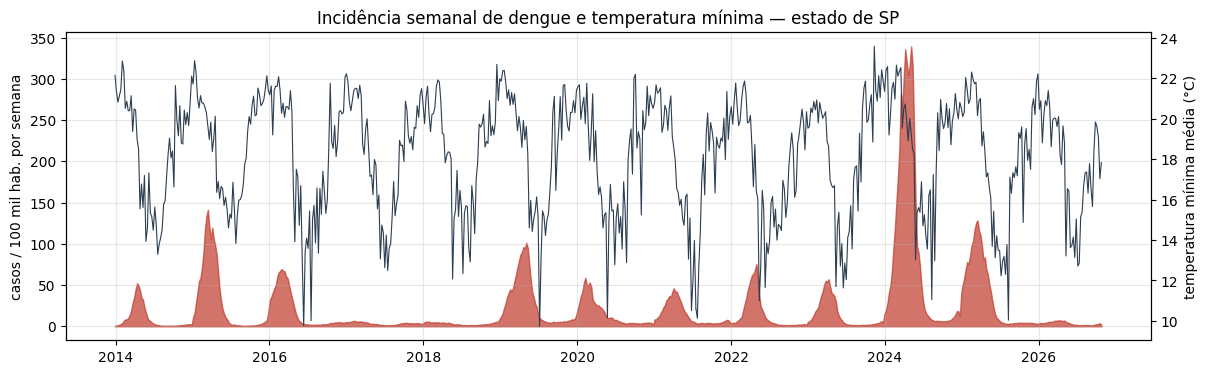

,casos,incidência / 100 mil
ano,,
2014,221908,504
2015,742040,1671
2016,456427,1020
2017,83268,185
2018,77463,170
2019,717144,1562
2020,396470,857
2021,347912,746
2022,350404,789


In [21]:
inc_estado = CASOS.sum(axis=1) / POP.sum(axis=1) * 1e5
fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.fill_between(semanas, inc_estado, color="#c0392b", alpha=0.7, label="incidência")
ax1.set_ylabel("casos / 100 mil hab. por semana")
ax2 = ax1.twinx()
ax2.plot(semanas, np.nanmean(CLIMA["temp_min"], axis=1), color="#2c3e50", lw=0.8, label="temp. mínima")
ax2.set_ylabel("temperatura mínima média (°C)"); ax2.grid(False)
ax1.set_title(f"Incidência semanal de dengue e temperatura mínima — estado de {UF_SIGLA}")
plt.show()

anual = pd.DataFrame({"casos": CASOS.sum(axis=1), "ano": ANO_EPI}).groupby("ano").casos.sum()
anual = pd.DataFrame({"casos": anual, "incidência / 100 mil": anual / pop_anual.loc[anual.index].sum(axis=1) * 1e5})
anual.round(0).astype(int)

### 6.2 Sazonalidade

Cada linha é uma temporada, da SE 41 à SE 40 do ano seguinte. O pico costuma cair entre as SE 10 e 18, de março a maio.

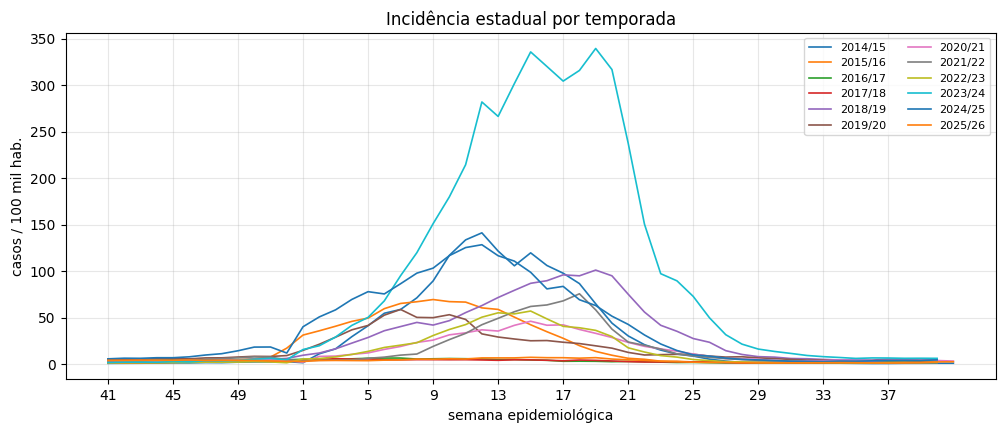

In [22]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for s in sorted(set(TEMPORADA)):
    l = np.where(TEMPORADA == s)[0]
    if len(l) >= 52:
        ax.plot(range(len(l)), inc_estado[l], lw=1.2, label=f"{s}/{str(s + 1)[2:]}")
pos = list(range(0, 52, 4))
ax.set_xticks(pos, [((40 + i) % 52) + 1 for i in pos])
ax.set(xlabel="semana epidemiológica", ylabel="casos / 100 mil hab.", title="Incidência estadual por temporada")
ax.legend(ncol=2, fontsize=8); plt.show()

### 6.3 Distribuição espacial

Incidência acumulada de cada município, ano a ano (escala logarítmica).

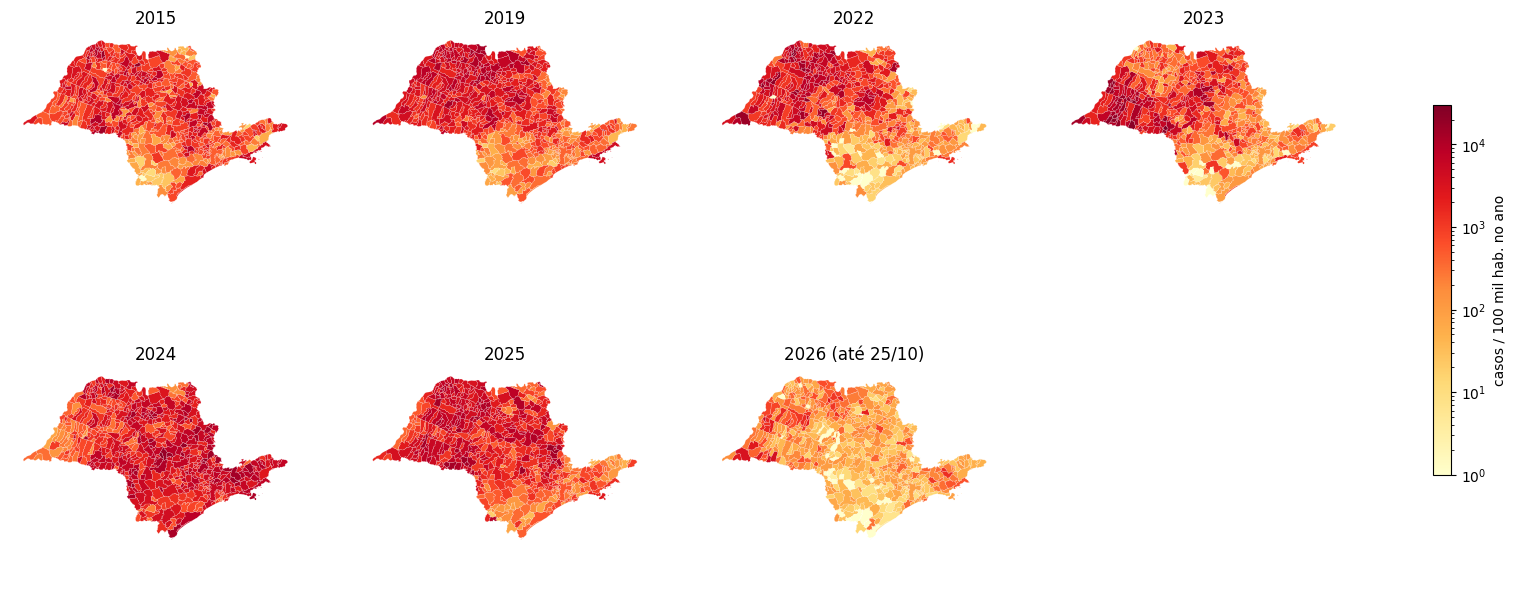

Maiores incidências entre municípios com mais de 100 mil habitantes:
2015                              Rio Claro (10,753), Catanduva (8,861), Sorocaba (8,812)
2019                             Araraquara (10,906), Votuporanga (10,733), Bauru (9,848)
2022                            Votuporanga (10,391), Araraquara (8,640), Birigui (8,121)
2023                           Presidente Prudente (15,730), Bauru (3,727), Assis (3,494)
2024             São José dos Campos (13,554), Jacareí (13,465), Pindamonhangaba (13,433)
2025    Mogi Guaçu (16,006), Presidente Prudente (12,836), São José do Rio Preto (10,804)
2026                      Birigui (1,472), Taubaté (1,355), São José do Rio Preto (1,155)


In [23]:
def desenhar_mapa(ax, valores, titulo, norma, cmap="YlOrRd"):
    patches, cores = [], []
    for g, v in zip(muns.geocodigo, valores):
        partes = getattr(geoms[g], "geoms", [geoms[g]])
        for p in partes:
            patches.append(MplPolygon(np.asarray(p.exterior.coords), closed=True))
            cores.append(v)
    pc = PatchCollection(patches, cmap=cmap, norm=norma, edgecolor="white", linewidth=0.1)
    pc.set_array(np.asarray(cores))
    ax.add_collection(pc)
    ax.autoscale_view(); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(titulo)
    return pc

anos_mapa = [a for a in (2015, 2019, 2022, 2023, 2024, 2025, 2026) if a in set(ANO_EPI)]
acum = {a: CASOS[ANO_EPI == a].sum(axis=0) / pop_anual.loc[a].to_numpy() * 1e5 for a in anos_mapa}
norma = mcolors.LogNorm(vmin=1, vmax=max(np.nanmax(v) for v in acum.values()))
ncol = int(np.ceil(len(anos_mapa) / 2))
fig, axs = plt.subplots(2, ncol, figsize=(5.4 * ncol, 8))
for ax in axs.ravel()[len(anos_mapa):]:
    ax.axis("off")
for ax, a in zip(axs.ravel(), anos_mapa):
    titulo = str(a) + (f" (até {semanas[-1]:%d/%m})" if a == ANO_EPI[-1] and semanas[-1].month < 12 else "")
    pc = desenhar_mapa(ax, np.clip(acum[a], 1, None), titulo, norma)
fig.colorbar(pc, ax=axs, shrink=0.6, label="casos / 100 mil hab. no ano")
plt.show()

top = (pd.DataFrame(acum, index=muns.nome)[POP[-1] >= 100_000]
         .apply(lambda s: ", ".join(f"{n} ({v:,.0f})" for n, v in s.nlargest(3).items())))
print("Maiores incidências entre municípios com mais de 100 mil habitantes:\n" + top.to_string())

### 6.4 Defasagem entre clima e casos

O efeito do clima demora a aparecer: o mosquito precisa se desenvolver, e o vírus precisa de tempo de incubação no mosquito e na pessoa. Para ver quantas semanas de defasagem trazem mais informação, calculamos a correlação de Spearman entre o clima da semana `t − lag` e a incidência da semana `t`, no período de treino e com todos os municípios.

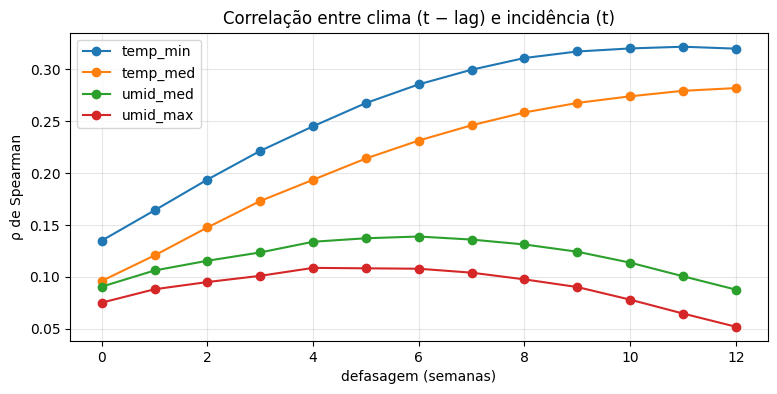

In [24]:
lin_treino = np.where(semanas <= TREINO_ATE)[0]
correl = {}
for v in ["temp_min", "temp_med", "umid_med", "umid_max"]:
    X, Y = CLIMA[v][lin_treino], INC[lin_treino]
    correl[v] = [stats.spearmanr(X[: len(X) - L].ravel(), Y[L:].ravel(), nan_policy="omit")[0] for L in range(13)]
ax = pd.DataFrame(correl).plot(marker="o", figsize=(9, 4))
ax.set(xlabel="defasagem (semanas)", ylabel="ρ de Spearman", title="Correlação entre clima (t − lag) e incidência (t)")
plt.show()

## 7. Número reprodutivo efetivo (Rt)

O Rt é o número médio de pessoas que cada caso infecta. Com Rt > 1 a transmissão está crescendo; com Rt < 1, está caindo.

Usamos o método de Cori et al. (2013), o mesmo do pacote EpiEstim:

$$\Lambda_t = \sum_{s=1}^{6} w_s\, I_{t-s}, \qquad R_t \sim \text{Gama}\!\left(a_0 + \sum_{j=t-2}^{t} I_j,\ \ \text{taxa} = \frac{1}{b_0} + \sum_{j=t-2}^{t} \Lambda_j\right)$$

- $I_t$ são os casos na semana $t$;
- $w_s$ é o intervalo de geração da dengue, ou seja, o tempo entre a infecção de uma pessoa e a de quem ela infecta. Aqui ele é discretizado em semanas, com distribuição normal de média 3 e desvio de 1 semana;
- a janela é de 3 semanas, e a distribuição *a priori* é Gama($a_0 = 1$, $b_0 = 5$);
- $p_1 = P(R_t > 1)$ é a probabilidade de a transmissão estar crescendo. Valores de $p_1$ acima de 0,95 são tratados como evidência de transmissão sustentada.

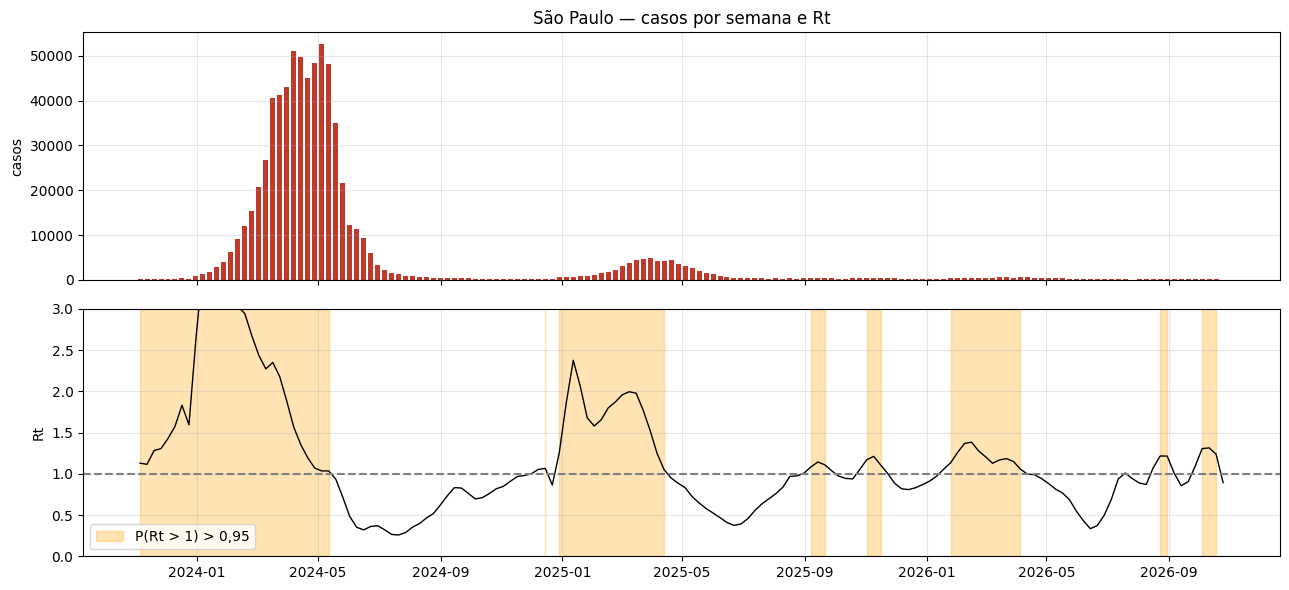

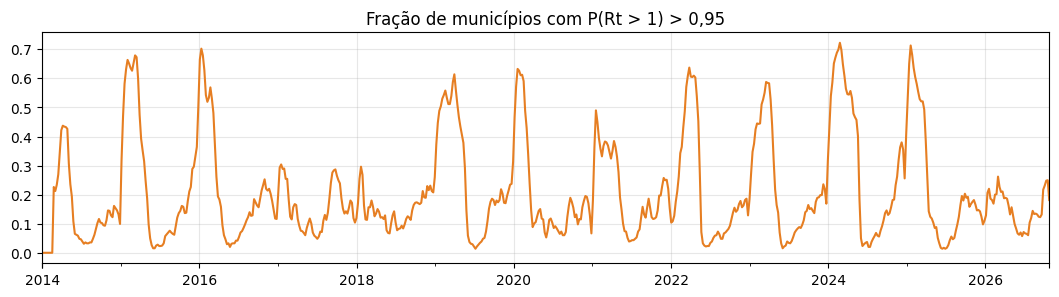

In [25]:
def deslocar(X, s):
    """Desloca uma matriz (semanas × municípios) s semanas para baixo (s > 0) ou para cima (s < 0)."""
    Y = np.full(X.shape, np.nan)
    if s > 0:
        Y[s:] = X[:-s]
    elif s < 0:
        Y[:s] = X[-s:]
    else:
        Y[:] = X
    return Y


def soma_movel(X, n):
    return pd.DataFrame(X).rolling(n, min_periods=n).sum().to_numpy()


W_GI = stats.norm.pdf(np.arange(1, 7), 3, 1)
W_GI /= W_GI.sum()


def estimar_rt(I, janela=3, a0=1.0, b0=5.0):
    lam = sum(W_GI[s - 1] * deslocar(I, s) for s in range(1, len(W_GI) + 1))
    forma, taxa = a0 + soma_movel(I, janela), 1 / b0 + soma_movel(lam, janela)
    return forma / taxa, stats.gamma.sf(1, forma, scale=1 / taxa)


RT, P1 = estimar_rt(CASOS)

n = 156
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].bar(semanas[-n:], CASOS[-n:, CAPITAL], width=5, color="#c0392b")
ax[0].set(title=f"{muns.nome[CAPITAL]} — casos por semana e Rt", ylabel="casos")
ax[1].plot(semanas[-n:], RT[-n:, CAPITAL], color="k", lw=1)
ax[1].axhline(1, color="grey", ls="--")
ax[1].fill_between(semanas[-n:], 0, 3, where=P1[-n:, CAPITAL] > 0.95, color="orange", alpha=0.3, label="P(Rt > 1) > 0,95")
ax[1].set(ylim=(0, 3), ylabel="Rt"); ax[1].legend()
plt.tight_layout(); plt.show()

frac = pd.Series((P1 > 0.95).mean(axis=1), index=semanas)
frac.plot(figsize=(13, 3), color="#e67e22", title="Fração de municípios com P(Rt > 1) > 0,95")
plt.show()

## 8. Limiares epidêmicos

Os limiares dizem o que é incidência normal, elevada e epidêmica em cada município. Para calculá-los, implementamos uma versão do Moving Epidemic Method (MEM, Vega et al., 2013):

1. Em cada temporada, o período epidêmico é o bloco de `r` semanas seguidas com a maior soma de incidência. O tamanho `r` vem da curva MAP (porcentagem acumulada máxima): o bloco para de crescer quando mais uma semana aumentaria a porcentagem em menos de 2,8%.
2. As semanas antes do bloco são pré-epidêmicas, e as depois dele, pós-epidêmicas.
3. De cada temporada entram os `n ≈ 30 / nº de temporadas` maiores valores de cada fase.

| Limiar | Cálculo |
|---|---|
| `limiar_pre` | limite superior do IC 95% unilateral da média aritmética dos maiores valores pré-epidêmicos |
| `limiar_pos` | o mesmo cálculo, com os valores pós-epidêmicos |
| `limiar_epidemico` | limite superior do IC 90% unilateral da média geométrica dos maiores valores epidêmicos |

Os limiares usam só temporadas completas do período de treino, para que nenhuma informação da avaliação vaze para eles. Municípios com menos de 3 temporadas de pelo menos 20 casos recebem a mediana dos limiares dos outros.

In [26]:
def ls_media(v, nivel):
    v = np.asarray(v, float)
    return np.nan if len(v) < 3 else v.mean() + stats.t.ppf(nivel, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))


def ls_geometrica(v, nivel):
    v = np.log(np.asarray(v, float)[np.asarray(v, float) > 0])
    return np.nan if len(v) < 3 else float(np.exp(v.mean() + stats.t.ppf(nivel, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))))


def limiares_mem(inc, casos, temporadas, delta=2.8, min_casos=20, min_temporadas=3):
    n_top = max(1, round(30 / len(temporadas)))
    fases = {f: [[] for _ in range(M)] for f in ("pre", "epi", "pos")}
    n_temp = np.zeros(M, int)
    for s in temporadas:
        linhas = np.where(TEMPORADA == s)[0]
        X, L = np.nan_to_num(inc[linhas]), len(linhas)
        total = X.sum(axis=0)
        acum = np.vstack([np.zeros(M), X.cumsum(axis=0)])
        max_soma, inicio = np.zeros((L, M)), np.zeros((L, M), int)
        for r in range(1, L + 1):                       # maior soma em r semanas seguidas
            somas = acum[r:] - acum[:-r]
            max_soma[r - 1], inicio[r - 1] = somas.max(axis=0), somas.argmax(axis=0)
        mapc = 100 * max_soma / np.where(total > 0, total, np.nan)
        incremento = np.diff(np.vstack([np.zeros(M), mapc]), axis=0)
        abaixo = np.nan_to_num(incremento, nan=0) < delta
        r_otimo = np.where(abaixo.any(axis=0), np.maximum(1, abaixo.argmax(axis=0)), L)
        for m in np.where(casos[linhas].sum(axis=0) >= min_casos)[0]:
            r, i0 = r_otimo[m], inicio[r_otimo[m] - 1, m]
            for f, vals in (("pre", X[:i0, m]), ("epi", X[i0:i0 + r, m]), ("pos", X[i0 + r:, m])):
                fases[f][m].extend(np.sort(vals)[-n_top:])
            n_temp[m] += 1
    lim = pd.DataFrame({"limiar_pre": [ls_media(v, 0.95) for v in fases["pre"]],
                        "limiar_pos": [ls_media(v, 0.95) for v in fases["pos"]],
                        "limiar_epidemico": [ls_geometrica(v, 0.90) for v in fases["epi"]],
                        "n_temporadas": n_temp}, index=muns.geocodigo)
    proprio = lim.n_temporadas >= min_temporadas
    for c in ["limiar_pre", "limiar_pos", "limiar_epidemico"]:
        lim.loc[~proprio | lim[c].isna(), c] = lim.loc[proprio, c].median()
    lim["limiar_epidemico"] = np.maximum(lim.limiar_epidemico, lim.limiar_pre)
    lim["limiar_proprio"] = proprio
    return lim


TEMPORADAS_TREINO = [int(s) for s in sorted(set(TEMPORADA))
                     if (TEMPORADA == s).sum() >= 52 and semanas[TEMPORADA == s].max() <= TREINO_ATE]
LIM = limiares_mem(INC, CASOS, TEMPORADAS_TREINO)
print(f"Temporadas de treino: {TEMPORADAS_TREINO}")
print(f"Municípios com limiares próprios: {LIM.limiar_proprio.sum()} de {M}")
LIM.join(muns.set_index("geocodigo").nome)[POP[-1] >= 100_000].sort_values("limiar_epidemico", ascending=False).head(10).round(2)

Temporadas de treino: [2014, 2015, 2016, 2017, 2018, 2019, 2020]
Municípios com limiares próprios: 561 de 645


,limiar_pre,limiar_pos,limiar_epidemico,n_temporadas,limiar_proprio,nome
geocodigo,,,,,,
3549805,91.25,104.44,233.86,7,True,São José do Rio Preto
3557105,107.14,95.40,207.76,7,True,Votuporanga
3506508,91.96,78.14,194.97,7,True,Birigui
3541406,75.80,65.73,182.81,7,True,Presidente Prudente
3511102,68.59,96.64,180.90,7,True,Catanduva
3530706,67.64,67.83,154.80,7,True,Mogi Guaçu
3510500,75.92,62.34,132.42,7,True,Caraguatatuba
3529005,44.54,45.26,110.80,7,True,Marília
3504008,36.90,30.35,110.33,7,True,Assis


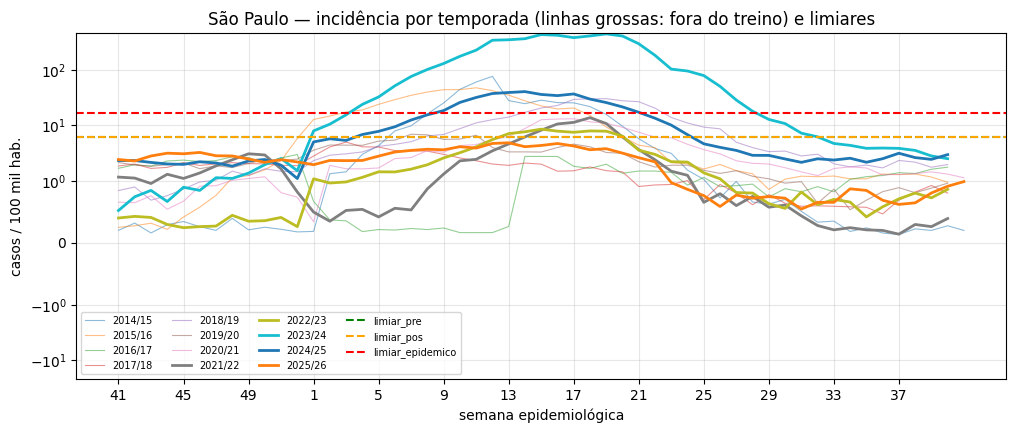

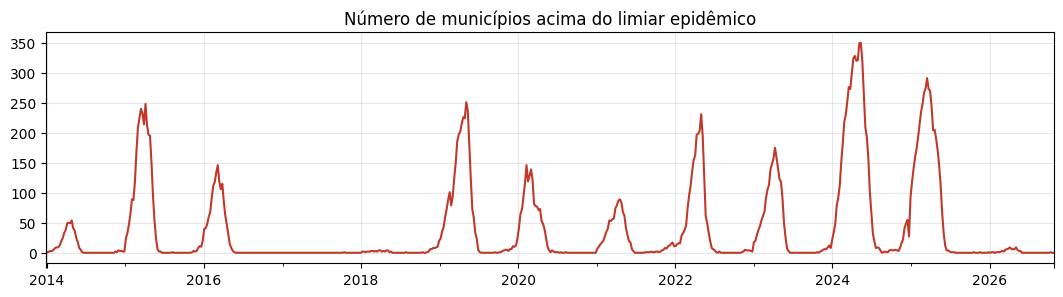

In [27]:
# Diagrama de controle: temporadas da capital com os limiares
m = CAPITAL
fig, ax = plt.subplots(figsize=(12, 4.5))
for s in sorted(set(TEMPORADA)):
    l = np.where(TEMPORADA == s)[0]
    if len(l) >= 52:
        ax.plot(range(len(l)), INC[l, m], lw=2 if s > TEMPORADAS_TREINO[-1] else 0.8,
                alpha=1 if s > TEMPORADAS_TREINO[-1] else 0.5, label=f"{s}/{str(s + 1)[2:]}")
for c, cor in [("limiar_pre", "green"), ("limiar_pos", "orange"), ("limiar_epidemico", "red")]:
    ax.axhline(LIM.iloc[m][c], color=cor, ls="--", label=c)
pos = list(range(0, 52, 4))
ax.set_xticks(pos, [((40 + i) % 52) + 1 for i in pos])
ax.set_yscale("symlog", linthresh=1)
ax.set(xlabel="semana epidemiológica", ylabel="casos / 100 mil hab.",
       title=f"{muns.nome[m]} — incidência por temporada (linhas grossas: fora do treino) e limiares")
ax.legend(ncol=4, fontsize=7); plt.show()

acima = pd.Series(((INC > LIM.limiar_epidemico.values) & (CASOS > 10)).sum(axis=1), index=semanas)
acima.plot(figsize=(13, 3), color="#c0392b", title="Número de municípios acima do limiar epidêmico")
plt.show()

## 9. Formulação dos modelos

### 9.1 Problema

Em cada semana de referência `T` (o "hoje" de quem faz a previsão), o objetivo é prever a semana `T + h`, com `h` igual a 1 ou 4:

- na regressão, a incidência de dengue na semana `T + h`, com uma previsão central e uma faixa de incerteza;
- na classificação, se a semana `T + h` vai ficar acima do limiar epidêmico do município (incidência > `limiar_epidemico` e mais de 10 casos).

### 9.2 Variáveis preditoras

Todas usam só informação disponível na semana `T`:

| Grupo | Variáveis |
|---|---|
| Casos recentes | incidência das semanas `T` a `T−3` com os casos já digitados até `T`, a média das 4 e a tendência (últimas 2 semanas ÷ 2 anteriores) |
| Vizinhança | incidência recente média dos municípios vizinhos (os que fazem divisa) |
| Rt | Rt e P(Rt > 1) calculados com os casos já digitados até `T` |
| Limiares | log dos limiares pré-epidêmico e epidêmico do município; razão entre a incidência recente e o limiar epidêmico |
| Sazonalidade | incidência da mesma semana no ano anterior; seno e cosseno da SE da semana-alvo |
| Clima defasado | `temp_min`, `temp_med`, `temp_max`, `umid_med`, `umid_max`: semanas `T−1` a `T−4`, média de `T−1` a `T−4`, média de `T−5` a `T−8` e média de `T−9` a `T−12` |
| Município | log da população |

Os casos das últimas semanas ainda estão chegando ao sistema. Se usássemos a contagem final, o modelo veria, no treino e no teste, dados que ninguém teria na hora de prever. Por isso as variáveis usam os casos já digitados até `T`, que a matriz `C[t, m, k]` reconstrói semana a semana.

A vizinhança entra porque a dengue se espalha entre municípios próximos, e a situação dos vizinhos ajuda a prever a chegada de uma epidemia. Em estudos recentes para o Brasil, modelos que incluem a transmissão em áreas vizinhas tiveram desempenho melhor (Chen & Moraga, 2025).

As defasagens longas vêm da análise exploratória (seção 6.4), em que a temperatura mínima teve a maior correlação com a incidência de 8 a 12 semanas depois.

O ano não entra como variável, porque modelos de árvore não extrapolam para valores fora do intervalo do treino.

### 9.3 Alvo: o crescimento da incidência

Modelos de árvore não preveem valores maiores do que os que viram no treino. Com a incidência como alvo, todos os modelos subestimaram a epidemia de 2024, muito maior que qualquer ano anterior. A saída é prever o crescimento em relação ao nível atual:

$$r = \frac{\text{incidência}_{T+h} + 1}{\text{incidência recente}_T + 1}, \qquad \widehat{\text{incidência}}_{T+h} = (\text{incidência recente}_T + 1)\cdot \hat r - 1$$

Uma razão como "a incidência vai triplicar em 4 semanas" já aparece no treino. Quando ela é multiplicada por um nível recente alto, a previsão pode passar de tudo o que já se viu.

### 9.4 Avaliação em janelas móveis

O modelo é retreinado a cada ano com todos os dados disponíveis até ali (janela expansível) e testado no ano seguinte:

| Ano de teste | Treino (semanas-alvo) |
|---|---|
| 2023 | até 2022 |
| 2024 | até 2023 |
| 2025 | até 2024 |
| 2026 (até a última semana com dados) | até 2025 |

As últimas 8 semanas da base ficam fora do treino e da avaliação, porque ainda vão receber casos digitados com atraso. Elas continuam sendo usadas como ponto de partida das previsões.

É assim que um sistema de previsão em uso funciona: a cada temporada, o modelo aprende com os anos mais recentes. Os limiares epidêmicos continuam calculados só com as temporadas até 2021, para que a definição de semana epidêmica seja a mesma nos três anos de teste.

In [28]:
from shapely.strtree import STRtree


def plano(A):
    """(semanas × municípios) -> vetor, na ordem das linhas do painel."""
    return np.asarray(A, float).ravel()


def casos_vistos_em_T(j):
    """Casos da semana T−j que já estavam digitados na semana T."""
    return deslocar(C[:, :, min(j, MAX_ATRASO)].astype(float), j)


def rt_aparente(janela=3, a0=1.0, b0=5.0, fim=1):
    """Rt com os casos conhecidos em T, janela terminando em T−fim."""
    V = {j: casos_vistos_em_T(j) for j in range(fim + janela + len(W_GI))}
    soma_i = sum(V[fim + i] for i in range(janela))
    soma_l = sum(W_GI[s - 1] * V[fim + i + s] for i in range(janela) for s in range(1, len(W_GI) + 1))
    forma, taxa = a0 + soma_i, 1 / b0 + soma_l
    return forma / taxa, stats.gamma.sf(1, forma, scale=1 / taxa)


# Vizinhança: municípios que fazem divisa (ilhas e casos isolados recebem os 3 centroides mais próximos)
lista_geoms = [geoms[g] for g in muns.geocodigo]
centroides = np.array([[p.centroid.x, p.centroid.y] for p in lista_geoms])
arvore = STRtree(lista_geoms)
W_VIZ = np.zeros((M, M), dtype=np.float32)
for i, g in enumerate(lista_geoms):
    viz = [j for j in arvore.query(g.buffer(0.002), predicate="intersects") if j != i]
    if not viz:
        d = ((centroides - centroides[i]) ** 2).sum(axis=1); d[i] = np.inf
        viz = list(np.argsort(d)[:3])
    W_VIZ[i, viz] = 1
W_VIZ /= W_VIZ.sum(axis=1, keepdims=True)
print(f"Vizinhos por município: média {(W_VIZ > 0).sum(axis=1).mean():.1f}")

RT_AP, P1_AP = rt_aparente()
LIM_PRE, LIM_EPI = LIM.limiar_pre.to_numpy(), LIM.limiar_epidemico.to_numpy()
VARS_MODELO_CLIMA = ["temp_min", "temp_med", "temp_max", "umid_med", "umid_max"]
INC_REC = {j: casos_vistos_em_T(j) / POP * 1e5 for j in range(4)}
INC_REC_MEDIA = np.mean([INC_REC[j] for j in range(4)], axis=0)
C_INC = 1.0                                        # constante da razão de crescimento (casos / 100 mil)


def montar_painel(h):
    col = {f"inc_recente_{j}": plano(INC_REC[j]) for j in range(4)}
    col["inc_recente_media4"] = plano(INC_REC_MEDIA)
    col["tendencia_recente"] = plano(np.log((INC_REC[0] + INC_REC[1] + 2 * C_INC) / (INC_REC[2] + INC_REC[3] + 2 * C_INC)))
    col["inc_vizinhos_media4"] = plano(INC_REC_MEDIA @ W_VIZ.T)
    col["rt"] = plano(np.clip(RT_AP, 0, 10))
    col["p_rt_maior_1"] = plano(P1_AP)
    col["log_limiar_pre"] = plano(np.log1p(np.broadcast_to(LIM_PRE, (T, M))))
    col["log_limiar_epi"] = plano(np.log1p(np.broadcast_to(LIM_EPI, (T, M))))
    col["razao_limiar_epi"] = col["inc_recente_media4"] / plano(np.broadcast_to(LIM_EPI, (T, M)))
    col["inc_ano_anterior"] = plano(deslocar(INC, 52 - h))                       # semana T+h−52 (já completa)
    col["inc_ano_anterior_3sem"] = plano(np.nanmean([deslocar(INC, 52 - h + d) for d in (-1, 0, 1)], axis=0))
    se_alvo = deslocar(SE[:, None].astype(float), -h)
    col["se_sin"] = plano(np.broadcast_to(np.sin(2 * np.pi * se_alvo / 52.18), (T, M)))
    col["se_cos"] = plano(np.broadcast_to(np.cos(2 * np.pi * se_alvo / 52.18), (T, M)))
    col["log_pop"] = plano(np.log(POP))
    for v in VARS_MODELO_CLIMA:
        defas = {L: deslocar(CLIMA[v], L) for L in range(1, 13)}
        for L in range(1, 5):
            col[f"{v}_lag{L}"] = plano(defas[L])
        col[f"{v}_media_1a4"] = plano(np.nanmean([defas[L] for L in range(1, 5)], axis=0))
        col[f"{v}_media_5a8"] = plano(np.nanmean([defas[L] for L in range(5, 9)], axis=0))
        col[f"{v}_media_9a12"] = plano(np.nanmean([defas[L] for L in range(9, 13)], axis=0))
    df = pd.DataFrame(col)
    df["m"] = np.tile(np.arange(M), T)
    df["semana_alvo"] = np.repeat(pd.Series(semanas).shift(-h).to_numpy(), M)
    df["pop_alvo"] = plano(deslocar(POP, -h))
    df["y"] = plano(deslocar(INC, -h))
    df["evento"] = plano((deslocar(INC, -h) > LIM_EPI) & (deslocar(CASOS, -h) > 10))
    return df


COLS_EXTRA = ("m", "semana_alvo", "pop_alvo", "y", "evento")


def preparar(df):
    feats = [c for c in df.columns if c not in COLS_EXTRA]
    completas = df.semana_alvo <= semanas[-1] - pd.Timedelta(weeks=SEMANAS_INCOMPLETAS)
    base = df[completas & df.y.notna() & df.inc_recente_3.notna() & df.inc_ano_anterior.notna()
              & df.p_rt_maior_1.notna()].copy()
    ref = base.semana_alvo <= TREINO_ATE
    for c in [c for c in feats if c.startswith(("temp", "umid"))]:     # clima ausente -> média até 2021
        base[c] = base[c].fillna(base.loc[ref, c].mean())
    return feats, base


ANOS_TESTE = list(range(2023, ANO_FIM + 1))


def janela(base, ano):
    """Treino: semanas-alvo até 31/12 do ano anterior. Teste: semanas-alvo do ano."""
    fim_treino = pd.Timestamp(f"{ano - 1}-12-31")
    return (base[base.semana_alvo <= fim_treino],
            base[(base.semana_alvo > fim_treino) & (base.semana_alvo <= pd.Timestamp(f"{ano}-12-31"))])


def variaveis_lineares(df):
    """Conjunto enxuto e não redundante para os modelos lineares, com log nas variáveis muito assimétricas."""
    return pd.DataFrame({
        "log_inc_recente": np.log1p(df.inc_recente_media4),
        "tendencia_recente": df.tendencia_recente,
        "log_inc_vizinhos": np.log1p(df.inc_vizinhos_media4),
        "log_inc_ano_anterior": np.log1p(df.inc_ano_anterior_3sem),
        "log_razao_limiar_epi": np.log1p(df.razao_limiar_epi),
        "p_rt_maior_1": df.p_rt_maior_1,
        "se_sin": df.se_sin, "se_cos": df.se_cos,
        "log_pop": df.log_pop,
        "temp_min_1a4": df.temp_min_media_1a4, "temp_min_9a12": df.temp_min_media_9a12,
        "umid_med_1a4": df.umid_med_media_1a4, "umid_med_9a12": df.umid_med_media_9a12,
    }, index=df.index)


PAINEIS = {}
for h in HORIZONTES:
    FEATS, PAINEIS[h] = preparar(montar_painel(h))
    print(f"h = {h}: {len(PAINEIS[h]):,} linhas | {len(FEATS)} variáveis | "
          f"teste por ano: {[len(janela(PAINEIS[h], a)[1]) for a in ANOS_TESTE]}")

Vizinhos por município: média 5.7
h = 1: 393,450 linhas | 52 variáveis | teste por ano: [34185, 33540, 33540, 22575]
h = 4: 393,450 linhas | 52 variáveis | teste por ano: [34185, 33540, 33540, 22575]


## 10. Regressão: incidência `h` semanas à frente

### 10.1 Modelos

| Modelo | Descrição |
|---|---|
| Persistência (*baseline*) | repete a média das últimas 4 semanas com os casos já digitados |
| Sazonal (*baseline*) | repete a mesma semana do ano anterior |
| Regressão linear | modelo linear (mínimos quadrados) sobre o log da razão de crescimento, com proteção contra extrapolação (explicada abaixo). Usa 13 variáveis padronizadas e pouco redundantes: incidências em log, tendência, vizinhos, Rt, sazonalidade, população e as médias de temperatura mínima e umidade em 1 a 4 e 9 a 12 semanas. É o modelo mais simples e o mais fácil de interpretar, já que cada coeficiente diz quanto o crescimento esperado muda quando a variável sobe um desvio-padrão (seção 10.5). Variáveis muito correlacionadas entre si ficaram de fora porque deixariam os coeficientes instáveis |
| GB Poisson (nível) | Gradient Boosting com perda de Poisson prevendo diretamente a incidência |
| GB Poisson (crescimento) | Gradient Boosting com perda de Poisson prevendo a razão de crescimento *r* (seção 9.3) |
| RF (crescimento) | Random Forest prevendo a razão de crescimento *r* |
| Ensemble | média das três previsões acima. Combinar modelos diferentes costuma reduzir o erro, principalmente em surtos extremos |
| Quantis | Gradient Boosting com perda quantílica (quantis de 5%, 25%, 50%, 75% e 95% da razão de crescimento), que gera as faixas de 50% e 90% |

### 10.2 Métricas

As métricas são calculadas em número de casos (incidência × população ÷ 100 mil), tanto por município e semana quanto para o total do estado em cada semana:

- MAE: erro absoluto médio;
- RMSE: raiz do erro quadrático médio, que pesa mais os erros grandes;
- R²: fração da variação explicada. Vale 1 para uma previsão perfeita e 0 para quem prevê sempre a média, e fica negativo quando o modelo é pior que isso;
- MAE relativo: MAE do modelo dividido pelo MAE da persistência. Abaixo de 1, o modelo é melhor que o baseline;
- WIS (*Weighted Interval Score*): métrica para previsões com intervalo (Bracher et al., 2021). Junta o erro da mediana, a largura das faixas e uma penalidade quando o valor real cai fora delas. Para uma previsão sem intervalo, o WIS é igual ao erro absoluto, então dá para comparar com o MAE dos outros modelos;
- cobertura: fração das semanas em que o valor real caiu dentro da faixa de 50% e da de 90%. O ideal é ficar perto de 50% e 90%.

O treino completo (2 horizontes × 3 anos de teste) leva de 30 a 45 minutos no Colab. Os resultados ficam salvos no Drive (`dados/resultados_modelos`), e nas execuções seguintes esta etapa leva segundos. Para treinar de novo, por exemplo depois de mudar variáveis ou modelos, use `RETREINAR_MODELOS = True` na seção 3.

In [29]:
QUANTIS = [0.05, 0.25, 0.5, 0.75, 0.95]
MODELOS_PONTO = ["GB Poisson (nível)", "GB Poisson (crescimento)", "RF (crescimento)"]


def novos_regressores():
    gb = dict(loss="poisson", max_iter=300, learning_rate=0.08, max_leaf_nodes=63, min_samples_leaf=50,
              l2_regularization=1.0, early_stopping=False, random_state=RANDOM_STATE)
    return {"GB Poisson (nível)": HistGradientBoostingRegressor(**gb),
            "GB Poisson (crescimento)": HistGradientBoostingRegressor(**gb),
            "RF (crescimento)": RandomForestRegressor(n_estimators=80, min_samples_leaf=30, max_features=0.5,
                                                      max_samples=0.2, n_jobs=-1, random_state=RANDOM_STATE)}


def para_razao(y, base):
    return np.clip((y + C_INC) / (base + C_INC), 0, 100)


def de_razao(r, base):
    return np.clip((base + C_INC) * r - C_INC, 0, None)


def wis(y, q):
    """WIS com mediana e intervalos de 50% e 90%; y (n,), q (n, 5) nos QUANTIS."""
    m = q[:, 2]
    total = 0.5 * np.abs(y - m)
    for alfa, (lo, hi) in ((0.1, (0, 4)), (0.5, (1, 3))):
        l, u = q[:, lo], q[:, hi]
        intervalo = (u - l) + 2 / alfa * np.clip(l - y, 0, None) + 2 / alfa * np.clip(y - u, 0, None)
        total += alfa / 2 * intervalo
    return total / 2.5


import joblib

DIR_RES = DIR_DADOS / "resultados_modelos"
DIR_RES.mkdir(parents=True, exist_ok=True)
RES, ULTIMOS_MODELOS = {}, {}
for h in HORIZONTES:
    sufixo = f"h{h}_ate{semanas[-1]:%Y%m%d}"                       # novo corte de dados -> treina de novo
    arq_res, arq_mod = DIR_RES / f"regressao_{sufixo}.parquet", DIR_RES / f"modelos_{sufixo}.joblib"
    if arq_res.exists() and arq_mod.exists() and not RETREINAR_MODELOS:
        RES[h], ULTIMOS_MODELOS[h] = pd.read_parquet(arq_res), joblib.load(arq_mod)
        print(f"h = {h}: resultados carregados de {DIR_RES} (use RETREINAR_MODELOS = True para treinar de novo)")
        continue
    partes = []
    for ano in ANOS_TESTE:
        tr, te = janela(PAINEIS[h], ano)
        base_tr, base_te = tr.inc_recente_media4.to_numpy(), te.inc_recente_media4.to_numpy()
        r_tr = para_razao(tr.y.to_numpy(), base_tr)
        out = te[["semana_alvo", "m", "pop_alvo", "y", "evento", "razao_limiar_epi"]].copy()
        out["ano_teste"] = ano
        out["Persistência"] = base_te
        out["Sazonal (ano anterior)"] = te.inc_ano_anterior.to_numpy()
        modelos = novos_regressores()
        for nome, mod in modelos.items():
            if "nível" in nome:
                mod.fit(tr[FEATS], tr.y)
                out[nome] = np.clip(mod.predict(te[FEATS]), 0, None)
            else:
                mod.fit(tr[FEATS], r_tr)
                out[nome] = de_razao(mod.predict(te[FEATS]), base_te)
        out["Ensemble"] = out[MODELOS_PONTO].mean(axis=1)
        qs = []
        for q in QUANTIS:
            mq = HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=150, learning_rate=0.1,
                                               max_leaf_nodes=31, min_samples_leaf=100, random_state=RANDOM_STATE)
            mq.fit(tr[FEATS], r_tr)
            qs.append(de_razao(mq.predict(te[FEATS]), base_te))
        qs = np.sort(np.column_stack(qs), axis=1)             # garante quantis em ordem
        for q, col in zip(QUANTIS, qs.T):
            out[f"q{int(q * 100):02d}"] = col
        partes.append(out)
        ULTIMOS_MODELOS[h] = (modelos, te)
        print(f"h = {h}, teste {ano}: treino {len(tr):,} linhas, teste {len(te):,} — pronto", flush=True)
    RES[h] = pd.concat(partes, ignore_index=True)
    RES[h].to_parquet(arq_res, index=False)
    joblib.dump(ULTIMOS_MODELOS[h], arq_mod, compress=3)

h = 1, teste 2023: treino 269,610 linhas, teste 34,185 — pronto
h = 1, teste 2024: treino 303,795 linhas, teste 33,540 — pronto
h = 1, teste 2025: treino 337,335 linhas, teste 33,540 — pronto
h = 1, teste 2026: treino 370,875 linhas, teste 22,575 — pronto
h = 4, teste 2023: treino 269,610 linhas, teste 34,185 — pronto
h = 4, teste 2024: treino 303,795 linhas, teste 33,540 — pronto
h = 4, teste 2025: treino 337,335 linhas, teste 33,540 — pronto
h = 4, teste 2026: treino 370,875 linhas, teste 22,575 — pronto


#### Regressão linear

A regressão linear é ajustada separadamente porque é rápida, então não entra no cache acima. Modelos lineares extrapolam sem limite: se, num ano de teste, uma variável vai muito além do que existia no treino (como a incidência em 2024), a previsão pode explodir. Por isso usamos duas proteções comuns:
- cada variável é limitada ao intervalo observado no treino (percentis 0,1% e 99,9%);
- a previsão do log do crescimento também é limitada ao intervalo do treino.

Na volta da escala log, aplicamos a correção de viés de Duan, que é a média das exponenciais dos resíduos sem o 1% mais extremo de cada lado.

O ajuste é ponderado pela população do município, de modo que cada habitante pesa igual. Sem esse peso, os milhares de municípios pequenos dominam o ajuste. Como as métricas são calculadas em número de casos, um erro pequeno no crescimento previsto para uma cidade grande vira um erro enorme em casos.

In [30]:
def ajustar_linear(tr, te):
    Xtr, Xte = variaveis_lineares(tr), variaveis_lineares(te)
    lo, hi = Xtr.quantile(0.001), Xtr.quantile(0.999)
    Xtr, Xte = Xtr.clip(lo, hi, axis=1), Xte.clip(lo, hi, axis=1)
    alvo = np.log(para_razao(tr.y.to_numpy(), tr.inc_recente_media4.to_numpy()))
    peso = (tr.pop_alvo / tr.pop_alvo.mean()).to_numpy()          # cada habitante pesa igual
    modelo = make_pipeline(SimpleImputer(), StandardScaler(), LinearRegression()).fit(
        Xtr, alvo, linearregression__sample_weight=peso)
    residuos = alvo - modelo.predict(Xtr)
    duan = np.mean(np.exp(np.clip(residuos, *np.quantile(residuos, [0.01, 0.99]))))
    log_r = np.clip(modelo.predict(Xte), *np.quantile(alvo, [0.001, 0.999]))
    return modelo, de_razao(np.exp(log_r) * duan, te.inc_recente_media4.to_numpy())


for h in HORIZONTES:
    previsoes = []
    for ano in ANOS_TESTE:
        tr, te = janela(PAINEIS[h], ano)
        linear, p = ajustar_linear(tr, te)
        previsoes.append(p)
    RES[h]["Regressão linear"] = np.concatenate(previsoes)     # mesma ordem das linhas de RES[h]
    ULTIMOS_MODELOS[h][0]["Regressão linear"] = linear
    print(f"h = {h}: regressão linear ajustada nas {len(ANOS_TESTE)} janelas")

h = 1: regressão linear ajustada nas 4 janelas
h = 4: regressão linear ajustada nas 4 janelas


In [31]:
NOMES_PONTO = ["Persistência", "Sazonal (ano anterior)", "Regressão linear"] + MODELOS_PONTO + ["Ensemble"]


def metricas_regressao(d):
    fator = d.pop_alvo.to_numpy() / 1e5
    y = d.y.to_numpy() * fator
    tot_y = pd.Series(y).groupby(d.semana_alvo.to_numpy()).sum()
    linhas = {}
    for nome in NOMES_PONTO:
        pc = np.nan_to_num(d[nome].to_numpy()) * fator
        tot_p = pd.Series(pc).groupby(d.semana_alvo.to_numpy()).sum()
        linhas[nome] = {"MAE": mean_absolute_error(y, pc), "RMSE": np.sqrt(mean_squared_error(y, pc)),
                        "R²": r2_score(y, pc), "MAE estado": mean_absolute_error(tot_y, tot_p),
                        "R² estado": r2_score(tot_y, tot_p)}
    tab = pd.DataFrame(linhas).T
    tab["MAE relativo"] = tab["MAE"] / tab.loc["Persistência", "MAE"]
    qcasos = d[[f"q{int(q * 100):02d}" for q in QUANTIS]].to_numpy() * fator[:, None]
    tab["WIS"] = np.nan
    tab.loc["Quantis (mediana + faixas)", ["MAE", "WIS"]] = [mean_absolute_error(y, qcasos[:, 2]), wis(y, qcasos).mean()]
    for nome in NOMES_PONTO:
        tab.loc[nome, "WIS"] = tab.loc[nome, "MAE"]           # sem intervalo, WIS = erro absoluto
    tab.loc["Quantis (mediana + faixas)", "MAE relativo"] = tab.loc["Quantis (mediana + faixas)", "MAE"] / tab.loc["Persistência", "MAE"]
    return tab


def cobertura(d):
    y = d.y.to_numpy()
    return {"faixa 50%": np.mean((y >= d.q25) & (y <= d.q75)), "faixa 90%": np.mean((y >= d.q05) & (y <= d.q95))}


for h in HORIZONTES:
    d = RES[h]
    print(f"\n=== h = {h} semana(s) — teste {ANOS_TESTE[0]} a {ANOS_TESTE[-1]} (cada ano previsto por um modelo treinado até o ano anterior) ===")
    display(metricas_regressao(d).round(3))
    print("Cobertura das faixas:", {k: f"{v:.0%}" for k, v in cobertura(d).items()})
    por_ano = pd.DataFrame({ano: metricas_regressao(d[d.ano_teste == ano])["MAE relativo"] for ano in ANOS_TESTE})
    print(f"MAE relativo à persistência, por ano de teste (h = {h}):")
    display(por_ano.round(3))


=== h = 1 semana(s) — teste 2023 a 2026 (cada ano previsto por um modelo treinado até o ano anterior) ===


,MAE,RMSE,R²,MAE estado,R² estado,MAE relativo,WIS
Persistência,16.579,277.726,0.646,9456.078,0.574,1.000,16.579
Sazonal (ano anterior),44.529,620.205,-0.768,21850.016,-0.501,2.686,44.529
Regressão linear,14.459,177.385,0.855,6646.316,0.837,0.872,14.459
GB Poisson (nível),15.323,318.820,0.533,7244.116,0.677,0.924,15.323
GB Poisson (crescimento),13.614,256.966,0.697,6594.032,0.750,0.821,13.614
RF (crescimento),12.562,191.910,0.831,5652.497,0.846,0.758,12.562
Ensemble,13.345,251.173,0.710,6439.255,0.767,0.805,13.345
Quantis (mediana + faixas),13.950,NaN,NaN,NaN,NaN,0.841,9.453


Cobertura das faixas: {'faixa 50%': '59%', 'faixa 90%': '89%'}
MAE relativo à persistência, por ano de teste (h = 1):


,2023,2024,2025,2026
Persistência,1.000,1.000,1.000,1.000
Sazonal (ano anterior),2.085,1.637,4.421,25.146
Regressão linear,0.906,0.715,1.233,1.873
GB Poisson (nível),0.883,0.931,0.883,1.521
GB Poisson (crescimento),0.816,0.789,0.873,1.428
RF (crescimento),0.834,0.678,0.888,1.670
Ensemble,0.813,0.775,0.838,1.512
Quantis (mediana + faixas),0.842,0.856,0.796,0.931



=== h = 4 semana(s) — teste 2023 a 2026 (cada ano previsto por um modelo treinado até o ano anterior) ===


,MAE,RMSE,R²,MAE estado,R² estado,MAE relativo,WIS
Persistência,21.933,342.044,0.462,12500.711,0.373,1.000,21.933
Sazonal (ano anterior),44.529,620.205,-0.768,21850.016,-0.501,2.030,44.529
Regressão linear,20.347,334.368,0.486,10545.852,0.488,0.928,20.347
GB Poisson (nível),18.069,332.747,0.491,8259.508,0.659,0.824,18.069
GB Poisson (crescimento),17.787,318.229,0.535,8985.495,0.594,0.811,17.787
RF (crescimento),16.588,268.571,0.669,7997.784,0.724,0.756,16.588
Ensemble,16.922,300.525,0.585,8360.118,0.667,0.772,16.922
Quantis (mediana + faixas),17.999,NaN,NaN,NaN,NaN,0.821,12.936


Cobertura das faixas: {'faixa 50%': '58%', 'faixa 90%': '89%'}
MAE relativo à persistência, por ano de teste (h = 4):


,2023,2024,2025,2026
Persistência,1.000,1.000,1.000,1.000
Sazonal (ano anterior),1.524,1.272,3.141,20.193
Regressão linear,0.889,0.854,1.029,2.722
GB Poisson (nível),0.785,0.820,0.761,2.340
GB Poisson (crescimento),0.761,0.811,0.738,2.417
RF (crescimento),0.740,0.697,0.801,2.728
Ensemble,0.735,0.755,0.731,2.473
Quantis (mediana + faixas),0.765,0.856,0.733,1.151


### 10.3 Previsões no período de teste

À esquerda está o total do estado e, à direita, a capital, com as faixas de 50% e 90% do modelo quantílico. As linhas verticais marcam o começo de cada ano, quando o modelo é retreinado.

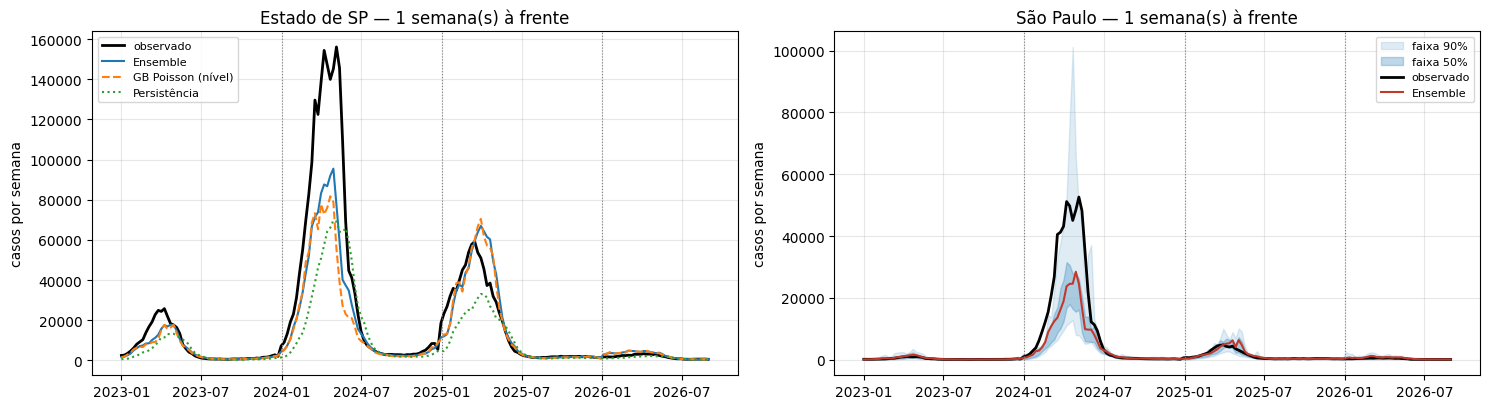

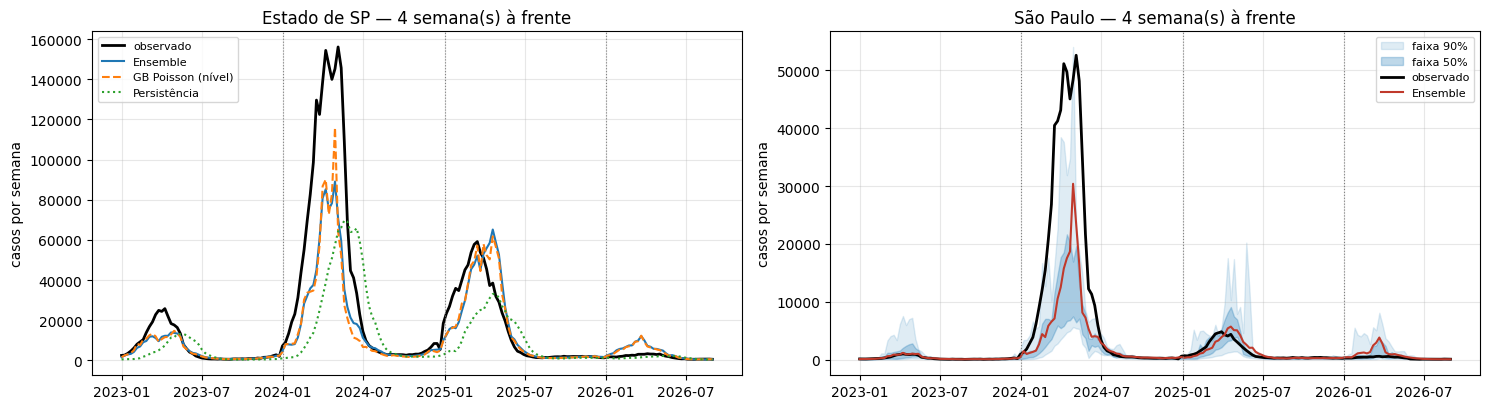

In [32]:
for h in HORIZONTES:
    d = RES[h]
    fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
    soma = lambda x, dd: pd.Series(np.nan_to_num(dd[x].to_numpy()) * dd.pop_alvo.to_numpy() / 1e5).groupby(dd.semana_alvo.to_numpy()).sum()
    ax = axs[0]
    ax.plot(soma("y", d), color="k", lw=2, label="observado")
    for nome, estilo in [("Ensemble", "-"), ("GB Poisson (nível)", "--"), ("Persistência", ":")]:
        ax.plot(soma(nome, d), estilo, label=nome)
    ax.set(title=f"Estado de {UF_SIGLA} — {h} semana(s) à frente", ylabel="casos por semana")
    cap = d[d.m == CAPITAL].sort_values("semana_alvo")
    f = cap.pop_alvo.to_numpy() / 1e5
    ax = axs[1]
    ax.fill_between(cap.semana_alvo, cap.q05 * f, cap.q95 * f, color="#2980b9", alpha=0.15, label="faixa 90%")
    ax.fill_between(cap.semana_alvo, cap.q25 * f, cap.q75 * f, color="#2980b9", alpha=0.3, label="faixa 50%")
    ax.plot(cap.semana_alvo, cap.y * f, color="k", lw=2, label="observado")
    ax.plot(cap.semana_alvo, cap.Ensemble * f, color="#c0392b", label="Ensemble")
    ax.set(title=f"{muns.nome[CAPITAL]} — {h} semana(s) à frente", ylabel="casos por semana")
    for a in axs:
        for ano in ANOS_TESTE[1:]:
            a.axvline(pd.Timestamp(f"{ano}-01-01"), color="grey", ls=":", lw=0.8)
        a.legend(fontsize=8)
    plt.tight_layout(); plt.show()

### 10.4 Importância das variáveis

A importância por permutação mede quanto o erro aumenta quando embaralhamos os valores de uma variável num conjunto que o modelo não viu. O cálculo é feito para o modelo de crescimento treinado até 2025, no teste de 2026.

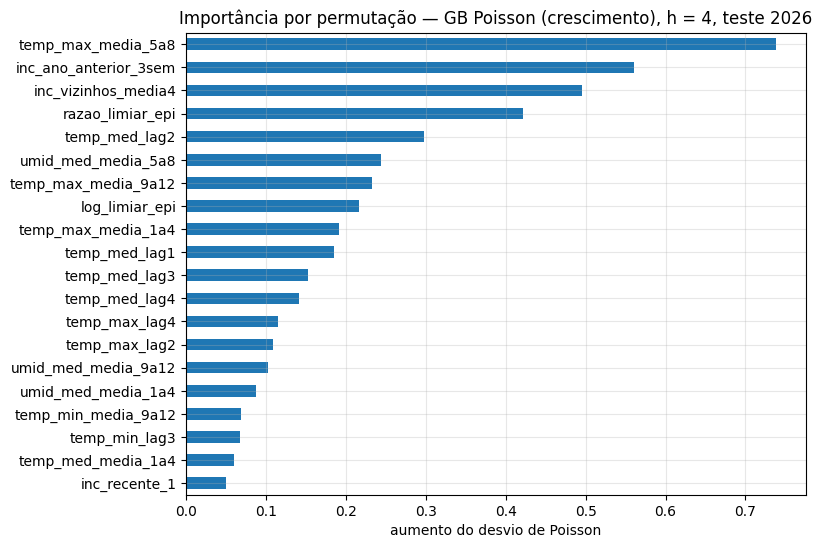

In [33]:
h = HORIZONTES[-1]
modelos, te = ULTIMOS_MODELOS[h]
mod = modelos["GB Poisson (crescimento)"]
amostra = te.sample(min(20_000, len(te)), random_state=RANDOM_STATE)
r_amostra = para_razao(amostra.y.to_numpy(), amostra.inc_recente_media4.to_numpy())
imp = permutation_importance(mod, amostra[FEATS], r_amostra, n_repeats=5, random_state=RANDOM_STATE,
                             scoring="neg_mean_poisson_deviance", n_jobs=-1)
ax = pd.Series(imp.importances_mean, index=FEATS).sort_values().tail(20).plot.barh(figsize=(8, 6))
ax.set(title=f"Importância por permutação — GB Poisson (crescimento), h = {h}, teste {ANOS_TESTE[-1]}",
       xlabel="aumento do desvio de Poisson")
plt.show()

### 10.5 Interpretação da regressão linear

Como ler as métricas das tabelas da seção 10.2:
- O MAE é o erro típico, em casos, por município e semana. Um MAE de 20 quer dizer que a previsão erra, em média, 20 casos para mais ou para menos.
- O RMSE pesa mais os erros grandes. Quando ele fica muito acima do MAE, os erros estão concentrados em poucas semanas de pico.
- O R² é a fração da variação explicada. Abaixo de 0, o modelo é pior que prever a média.
- Um MAE relativo abaixo de 1 indica que o modelo é melhor que repetir as últimas semanas.

Como ler os coeficientes do gráfico abaixo: o modelo prevê o logaritmo do crescimento da incidência entre `T` e `T + h`, com todas as variáveis padronizadas (média 0 e desvio-padrão 1). Assim, um coeficiente β quer dizer que, quando a variável sobe um desvio-padrão, o crescimento esperado é multiplicado por $e^{\beta}$. Por exemplo, β = 0,10 corresponde a um crescimento cerca de 10,5% maior. Coeficientes positivos aumentam a previsão de casos, e negativos diminuem.

<small>Os coeficientes descrevem associações dentro do modelo e não devem ser lidos como causas. Ainda sobra alguma correlação entre as variáveis (entre temperatura e sazonalidade, por exemplo), então cada coeficiente vale "com as demais variáveis constantes".</small>

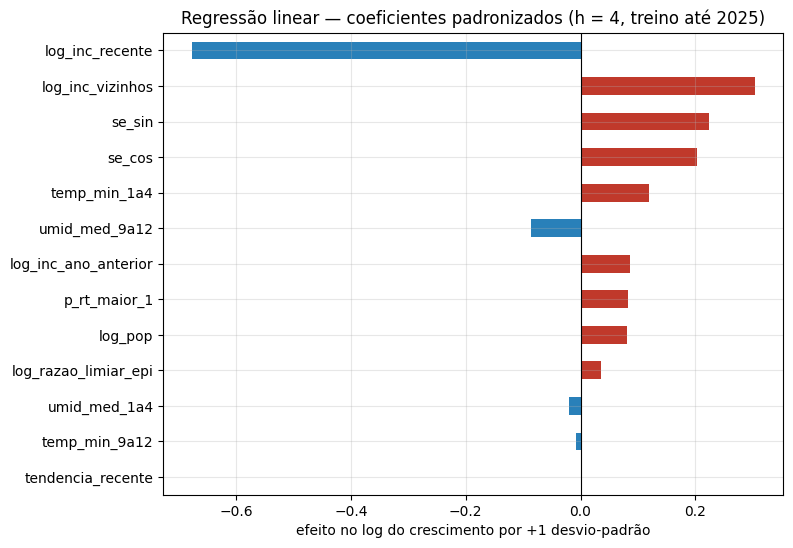

Regressão linear, h = 4, teste 2023 a 2026: MAE = 20.3 casos | RMSE = 334.4 casos | R² = 0.486
Maiores efeitos (crescimento multiplicado por, a cada +1 desvio-padrão):
  log_inc_recente              β = -0.678  →  ×0.51
  log_inc_vizinhos             β = +0.304  →  ×1.36
  se_sin                       β = +0.225  →  ×1.25
  se_cos                       β = +0.202  →  ×1.22
  temp_min_1a4                 β = +0.120  →  ×1.13


In [34]:
h = HORIZONTES[-1]
modelos, te = ULTIMOS_MODELOS[h]
linear = modelos["Regressão linear"]
coefs = pd.Series(linear[-1].coef_, index=variaveis_lineares(te.head(1)).columns)
top = coefs.reindex(coefs.abs().sort_values().index)
ax = top.plot.barh(figsize=(8, 6), color=np.where(top > 0, "#c0392b", "#2980b9"))
ax.axvline(0, color="k", lw=0.8)
ax.set(title=f"Regressão linear — coeficientes padronizados (h = {h}, treino até {ANOS_TESTE[-1] - 1})",
       xlabel="efeito no log do crescimento por +1 desvio-padrão")
plt.show()

d = RES[h]
fator = d.pop_alvo.to_numpy() / 1e5
y_c, p_c = d.y.to_numpy() * fator, d["Regressão linear"].to_numpy() * fator
print(f"Regressão linear, h = {h}, teste {ANOS_TESTE[0]} a {ANOS_TESTE[-1]}: MAE = {mean_absolute_error(y_c, p_c):.1f} casos | "
      f"RMSE = {np.sqrt(mean_squared_error(y_c, p_c)):.1f} casos | R² = {r2_score(y_c, p_c):.3f}")
print("Maiores efeitos (crescimento multiplicado por, a cada +1 desvio-padrão):")
for nome, b in coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(5).items():
    print(f"  {nome:28s} β = {b:+.3f}  →  ×{np.exp(b):.2f}")

## 11. Classificação: o município vai passar do limiar epidêmico?

Para a vigilância, saber com antecedência que um município vai entrar em situação epidêmica pode valer mais do que acertar o número exato de casos. O evento é *incidência > limiar epidêmico e mais de 10 casos* na semana `T + h`.

Como o evento é raro, usamos estas métricas:
- precisão: das semanas em que o modelo previu epidemia, quantas foram de fato epidêmicas;
- sensibilidade (*recall*): das semanas epidêmicas, quantas o modelo antecipou;
- F1: média harmônica das duas;
- AP (*average precision*): resume a curva precisão × sensibilidade e não depende do ponto de corte.

Os modelos comparados, todos nas mesmas janelas móveis, são:
- Persistência: prevê epidemia quando a incidência recente já está acima do limiar;
- Regressão logística: modelo linear para a probabilidade do evento, com as mesmas 13 variáveis padronizadas da regressão linear e pesos que equilibram as classes, já que o evento é raro. É o classificador mais simples e o mais fácil de interpretar. O ponto de corte é o que dá o maior F1 no treino de cada janela;
- Regressão (Ensemble): prevê epidemia quando a incidência prevista pelo ensemble passa do limiar;
- Gradient Boosting (classif.): treinado diretamente para o evento, também com pesos que equilibram as classes, e com ponto de corte 0,5.

In [35]:
def metricas_classif(y, escore, corte):
    prev = np.nan_to_num(escore) > corte
    return {"precisão": precision_score(y, prev, zero_division=0), "sensibilidade": recall_score(y, prev, zero_division=0),
            "F1": f1_score(y, prev, zero_division=0), "AP": average_precision_score(y, np.nan_to_num(escore))}


CLF = {}
def treinar_classificadores(h):
    """Gradient Boosting e regressão logística em cada janela; devolve os escores do teste e a última logística."""
    escores, escores_log = [], []
    for ano in ANOS_TESTE:
        tr, te = janela(PAINEIS[h], ano)
        clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
                                             class_weight="balanced", early_stopping=False, random_state=RANDOM_STATE)
        clf.fit(tr[FEATS], tr.evento)
        escores.append(clf.predict_proba(te[FEATS])[:, 1])
        logit = make_pipeline(SimpleImputer(), StandardScaler(),
                              LogisticRegression(class_weight="balanced", max_iter=2000, C=1.0))
        logit.fit(variaveis_lineares(tr), tr.evento)
        # ponto de corte: maior F1 no próprio treino (modelo linear simples, pouco sujeito a sobreajuste)
        p_tr, r_tr_, c_tr = precision_recall_curve(tr.evento, logit.predict_proba(variaveis_lineares(tr))[:, 1])
        f1_tr = 2 * p_tr * r_tr_ / np.where(p_tr + r_tr_ > 0, p_tr + r_tr_, 1)
        corte = c_tr[np.argmax(f1_tr[:-1])]
        escores_log.append(logit.predict_proba(variaveis_lineares(te))[:, 1] / corte * 0.5)   # corte do ano vira 0,5
    return np.concatenate(escores), np.concatenate(escores_log), logit


LOGITS = {}
for h in HORIZONTES:
    sufixo = f"h{h}_ate{semanas[-1]:%Y%m%d}"
    arq_cl, arq_lg = DIR_RES / f"classificacao_{sufixo}.parquet", DIR_RES / f"logistica_{sufixo}.joblib"
    if arq_cl.exists() and arq_lg.exists() and not RETREINAR_MODELOS:
        salvo = pd.read_parquet(arq_cl)
        esc_gb, esc_log, LOGITS[h] = salvo.gb.to_numpy(), salvo.logistica.to_numpy(), joblib.load(arq_lg)
    else:
        esc_gb, esc_log, LOGITS[h] = treinar_classificadores(h)
        pd.DataFrame({"gb": esc_gb, "logistica": esc_log}).to_parquet(arq_cl, index=False)
        joblib.dump(LOGITS[h], arq_lg, compress=3)
    d = RES[h]
    sc = {"Persistência": (d.razao_limiar_epi.to_numpy(), 1.0),
          "Regressão (Ensemble)": (d.Ensemble.to_numpy() / LIM_EPI[d.m.to_numpy()], 1.0),
          "Regressão logística": (esc_log, 0.5),
          "Gradient Boosting (classif.)": (esc_gb, 0.5)}
    y = d.evento.to_numpy().astype(bool)
    tab = pd.DataFrame({nome: metricas_classif(y, s, c) for nome, (s, c) in sc.items()}).T
    f1_ano = pd.DataFrame({ano: {nome: metricas_classif(y[d.ano_teste == ano], s[d.ano_teste == ano], c)["F1"]
                                 for nome, (s, c) in sc.items()} for ano in ANOS_TESTE})
    CLF[h] = {"escores": {k: v[0] for k, v in sc.items()}, "cortes": {k: v[1] for k, v in sc.items()}, "y": y}
    print(f"\n=== h = {h} semana(s) — teste {ANOS_TESTE[0]} a {ANOS_TESTE[-1]} ({int(y.sum()):,} semanas-município epidêmicas) ===")
    display(tab.round(3))
    print("F1 por ano de teste:")
    display(f1_ano.round(3))


=== h = 1 semana(s) — teste 2023 a 2026 (12,352 semanas-município epidêmicas) ===


,precisão,sensibilidade,F1,AP
Persistência,0.790,0.575,0.666,0.775
Regressão (Ensemble),0.779,0.769,0.774,0.851
Regressão logística,0.810,0.699,0.750,0.816
Gradient Boosting (classif.),0.613,0.908,0.732,0.873


F1 por ano de teste:


,2023,2024,2025,2026
Persistência,0.595,0.699,0.656,0.424
Regressão (Ensemble),0.719,0.804,0.765,0.547
Regressão logística,0.706,0.794,0.718,0.476
Gradient Boosting (classif.),0.705,0.787,0.696,0.321



=== h = 4 semana(s) — teste 2023 a 2026 (12,352 semanas-município epidêmicas) ===


,precisão,sensibilidade,F1,AP
Persistência,0.597,0.435,0.503,0.553
Regressão (Ensemble),0.712,0.656,0.683,0.756
Regressão logística,0.720,0.598,0.653,0.691
Gradient Boosting (classif.),0.514,0.861,0.643,0.773


F1 por ano de teste:


,2023,2024,2025,2026
Persistência,0.402,0.552,0.485,0.242
Regressão (Ensemble),0.584,0.715,0.694,0.317
Regressão logística,0.590,0.713,0.618,0.184
Gradient Boosting (classif.),0.576,0.717,0.633,0.136


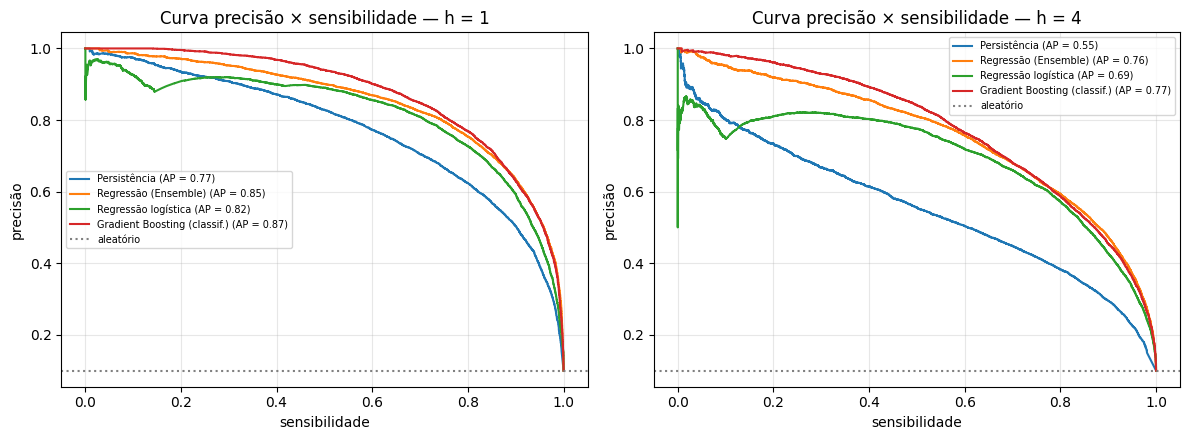

In [36]:
fig, axs = plt.subplots(1, len(HORIZONTES), figsize=(6 * len(HORIZONTES), 4.5), squeeze=False)
for ax, h in zip(axs[0], HORIZONTES):
    y = CLF[h]["y"]
    for nome, s in CLF[h]["escores"].items():
        p, r, _ = precision_recall_curve(y, np.nan_to_num(s))
        ax.plot(r, p, label=f"{nome} (AP = {average_precision_score(y, np.nan_to_num(s)):.2f})")
    ax.axhline(y.mean(), color="grey", ls=":", label="aleatório")
    ax.set(xlabel="sensibilidade", ylabel="precisão", title=f"Curva precisão × sensibilidade — h = {h}")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 11.1 Matrizes de confusão

Cada matriz divide as semanas-município do período de teste (2023 a 2026) em quatro grupos:
- verdadeiros negativos (canto superior esquerdo): não houve epidemia nem alerta;
- falsos positivos (superior direito): houve alerta sem epidemia, ou seja, um alarme falso;
- falsos negativos (inferior esquerdo): houve epidemia sem alerta, uma epidemia que o modelo não antecipou;
- verdadeiros positivos (inferior direito): a epidemia foi antecipada.

A precisão é VP ÷ (VP + FP), o recall (sensibilidade) é VP ÷ (VP + FN), e o F1 é a média harmônica dos dois.

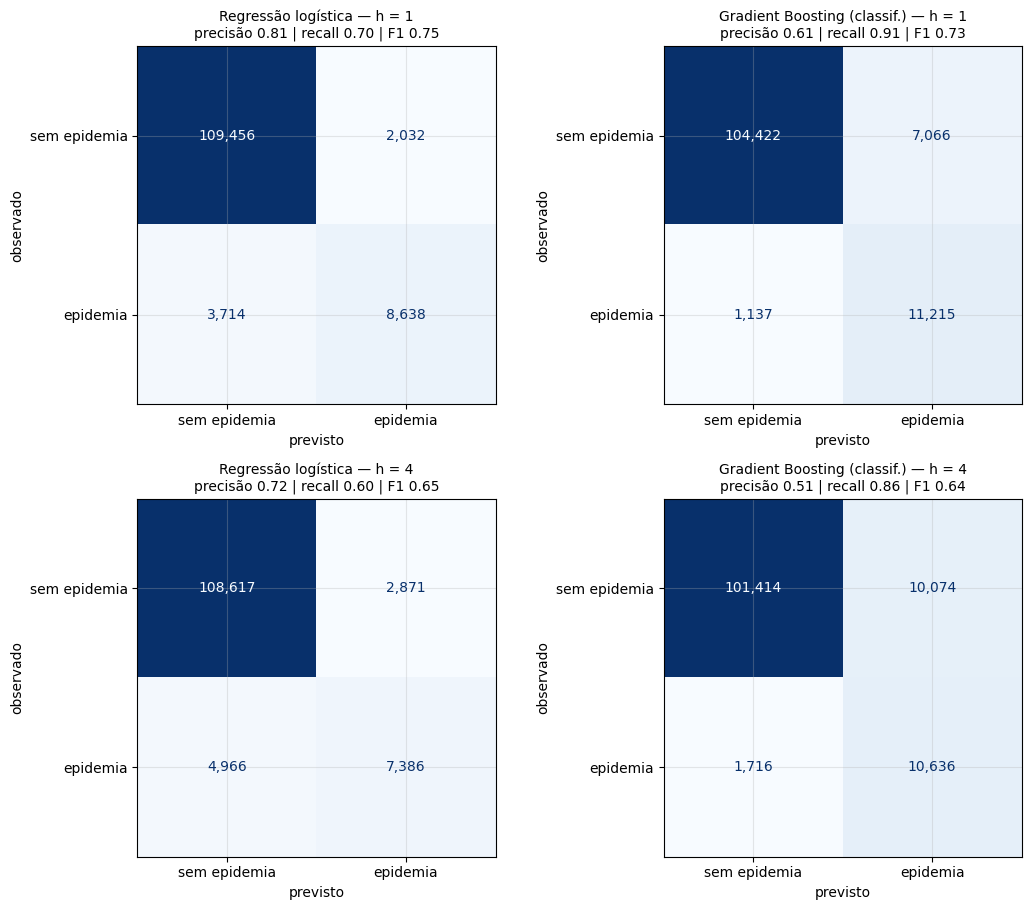

In [37]:
modelos_matriz = ["Regressão logística", "Gradient Boosting (classif.)"]
fig, axs = plt.subplots(len(HORIZONTES), len(modelos_matriz), figsize=(5.5 * len(modelos_matriz), 4.6 * len(HORIZONTES)), squeeze=False)
for i, h in enumerate(HORIZONTES):
    y = CLF[h]["y"]
    for j, nome in enumerate(modelos_matriz):
        prev = np.nan_to_num(CLF[h]["escores"][nome]) > CLF[h]["cortes"][nome]
        cm = confusion_matrix(y, prev, labels=[False, True])
        ConfusionMatrixDisplay(cm, display_labels=["sem epidemia", "epidemia"]).plot(ax=axs[i, j], cmap="Blues", colorbar=False, values_format=",d")
        vn, fp, fn, vp = cm.ravel()
        axs[i, j].set_title(f"{nome} — h = {h}\nprecisão {vp / max(vp + fp, 1):.2f} | recall {vp / max(vp + fn, 1):.2f} | "
                            f"F1 {2 * vp / max(2 * vp + fp + fn, 1):.2f}", fontsize=10)
        axs[i, j].set(xlabel="previsto", ylabel="observado")
plt.tight_layout(); plt.show()

### 11.2 Interpretação da regressão logística

Com as variáveis padronizadas, cada coeficiente da regressão logística vira uma razão de chance (*odds ratio*): $e^{\beta}$ é o fator que multiplica a chance de a semana ser epidêmica quando a variável sobe um desvio-padrão. Valores acima de 1 aumentam o risco, e abaixo de 1 reduzem.

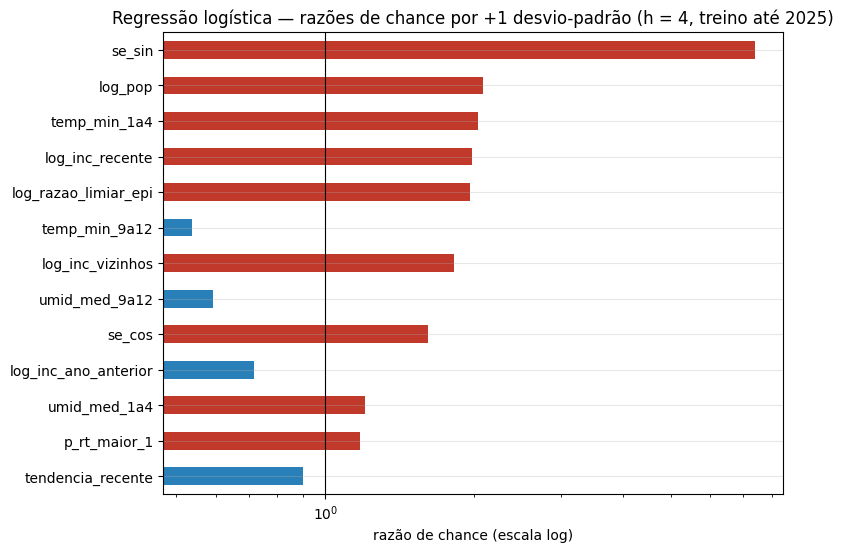

In [38]:
h = HORIZONTES[-1]
coefs_log = pd.Series(LOGITS[h][-1].coef_[0], index=variaveis_lineares(PAINEIS[h].head(1)).columns)
top = coefs_log.reindex(coefs_log.abs().sort_values().index)
ax = np.exp(top).plot.barh(figsize=(8, 6), color=np.where(top > 0, "#c0392b", "#2980b9"))
ax.axvline(1, color="k", lw=0.8)
ax.set_xscale("log")
ax.set(title=f"Regressão logística — razões de chance por +1 desvio-padrão (h = {h}, treino até {ANOS_TESTE[-1] - 1})",
       xlabel="razão de chance (escala log)")
plt.show()

## 12. Cenário sazonal com climatologia

Os modelos anteriores dependem dos casos recentes, então só conseguem prever poucas semanas à frente. Para um horizonte longo, de uma temporada inteira, o modelo abaixo usa só a sazonalidade, o perfil histórico do município e o clima:

- seno e cosseno da SE e log da população;
- incidência média do município e incidência média do município naquela SE, as duas calculadas só com o treino;
- clima com 1 a 4 semanas de defasagem.

No treino, o modelo usa o clima observado. Para projetar o futuro, quando o clima ainda não é conhecido, usamos a climatologia: a média histórica de cada variável por município e semana epidemiológica, calculada só com os anos de treino. Também mostramos o cenário com o clima que realmente aconteceu, para medir quanto saber o clima melhora a projeção.

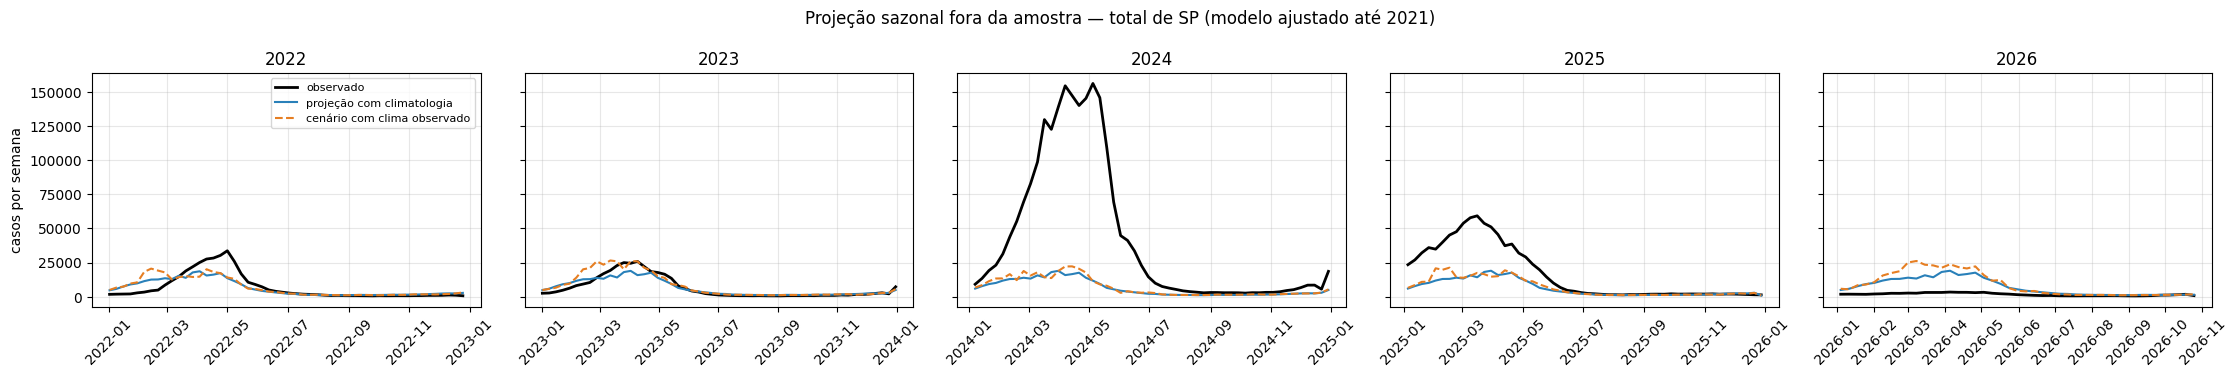

,MAE estado,R² estado
climatologia,11734.829,0.080
clima observado,11848.167,0.097


In [39]:
lin_tr = semanas <= TREINO_ATE


def media_por_se(X):
    """Valor médio de cada município em cada SE no treino, repetido para todas as semanas."""
    df = pd.DataFrame(X[lin_tr]); df["se"] = SE[lin_tr]
    return df.groupby("se").mean().reindex(range(1, 54)).ffill().bfill().to_numpy()[SE - 1]


CLIMATOLOGIA = {v: media_por_se(CLIMA[v]) for v in VARS_MODELO_CLIMA}
PERFIL_SE = media_por_se(INC)
MEDIA_MUN = np.broadcast_to(np.nanmean(INC[lin_tr], axis=0), (T, M))


def painel_sazonal(clima_usado):
    col = {"se_sin": plano(np.broadcast_to(np.sin(2 * np.pi * SE / 52.18)[:, None], (T, M))),
           "se_cos": plano(np.broadcast_to(np.cos(2 * np.pi * SE / 52.18)[:, None], (T, M))),
           "log_pop": plano(np.log(POP)), "inc_media_mun": plano(MEDIA_MUN), "inc_media_mun_se": plano(PERFIL_SE)}
    for v in VARS_MODELO_CLIMA:
        for L in range(1, 5):
            col[f"{v}_lag{L}"] = plano(deslocar(clima_usado[v], L))
    return pd.DataFrame(col)


X_obs, X_clim = painel_sazonal(CLIMA), painel_sazonal(CLIMATOLOGIA)
F_SAZ = list(X_obs.columns)
semana_lin = np.repeat(semanas.to_numpy(), M)
y_lin, pop_lin = plano(INC), plano(POP)
m_tr = (semana_lin <= TREINO_ATE.to_datetime64()) & X_obs.notna().all(axis=1).to_numpy() & np.isfinite(y_lin)
m_fut = semana_lin > TREINO_ATE.to_datetime64()

modelo_saz = HistGradientBoostingRegressor(loss="poisson", max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                           min_samples_leaf=100, early_stopping=False, random_state=RANDOM_STATE)
modelo_saz.fit(X_obs[m_tr], y_lin[m_tr])

proj = pd.DataFrame({"semana": semana_lin[m_fut],
                     "observado": y_lin[m_fut],
                     "climatologia": modelo_saz.predict(X_clim[m_fut]),
                     "clima observado": modelo_saz.predict(X_obs[m_fut].fillna(X_clim[m_fut]))})
for c in ["observado", "climatologia", "clima observado"]:
    proj[c] *= pop_lin[m_fut] / 1e5
tot = proj.groupby("semana").sum()

anos_proj = sorted(set(tot.index.year))
fig, axs = plt.subplots(1, len(anos_proj), figsize=(4.5 * len(anos_proj), 3.8), sharey=True)
for ax, ano in zip(np.atleast_1d(axs), anos_proj):
    d = tot[tot.index.year == ano]
    ax.plot(d.index, d["observado"], "k", lw=2, label="observado")
    ax.plot(d.index, d["climatologia"], color="#2980b9", label="projeção com climatologia")
    ax.plot(d.index, d["clima observado"], color="#e67e22", ls="--", label="cenário com clima observado")
    ax.set_title(str(ano)); ax.tick_params(axis="x", rotation=45)
np.atleast_1d(axs)[0].set_ylabel("casos por semana"); np.atleast_1d(axs)[0].legend(fontsize=8)
plt.suptitle(f"Projeção sazonal fora da amostra — total de {UF_SIGLA} (modelo ajustado até {TREINO_ATE.year})")
plt.tight_layout(); plt.show()

pd.DataFrame({c: {"MAE estado": mean_absolute_error(tot["observado"], tot[c]),
                  "R² estado": r2_score(tot["observado"], tot[c])} for c in ["climatologia", "clima observado"]}).T.round(3)

O modelo sazonal acerta quando a temporada acontece, mas não o tamanho de cada epidemia. A intensidade de cada ano depende de fatores que não estão nesta base, como o sorotipo em circulação, a imunidade da população e as ações de controle. Por isso a projeção com climatologia mostra um ano típico, e as previsões de curto prazo (seções 10 e 11) dependem dos casos recentes. Esta seção usa um único corte, com treino até 2021, porque o objetivo é medir só o sinal do clima.

## 13. Recomendações para a vigilância

Aqui as previsões viram ações. Os números vêm do período de teste (2023 a 2026), no horizonte de 4 semanas, que é o que dá tempo de agir.

In [40]:
h = HORIZONTES[-1]
y = CLF[h]["y"]
d = RES[h]
resumo = {}
for nome in ["Regressão logística", "Gradient Boosting (classif.)", "Persistência"]:
    prev = np.nan_to_num(CLF[h]["escores"][nome]) > CLF[h]["cortes"][nome]
    vn, fp, fn, vp = confusion_matrix(y, prev, labels=[False, True]).ravel()
    resumo[nome] = {"semanas epidêmicas antecipadas (%)": 100 * vp / max(vp + fn, 1),
                    "alertas confirmados (%)": 100 * vp / max(vp + fp, 1),
                    "alarmes falsos por alerta certo": fp / max(vp, 1),
                    "epidemias não antecipadas": fn}
display(pd.DataFrame(resumo).T.round(2))

fator = d.pop_alvo.to_numpy() / 1e5
y_c = d.y.to_numpy() * fator
dentro90 = np.mean((d.y >= d.q05) & (d.y <= d.q95))
acima90 = np.mean(d.y > d.q95)
print(f"Faixa de 90% (h = {h}): contém o valor real em {dentro90:.0%} das semanas-município; "
      f"o real fica ACIMA da faixa em {acima90:.0%}.")
pico = (d.assign(observado=d.y * d.pop_alvo / 1e5, ensemble=d.Ensemble * d.pop_alvo / 1e5)
          .groupby("semana_alvo")[["observado", "ensemble"]].sum())
semana_pico = pico.observado.idxmax()
print(f"Pico do teste: semana de {semana_pico.date()} — observado {pico.observado.max():,.0f} casos, "
      f"ensemble previu {pico.loc[semana_pico, 'ensemble']:,.0f} com {h} semanas de antecedência "
      f"({pico.loc[semana_pico, 'ensemble'] / pico.observado.max():.0%} do real).")

,semanas epidêmicas antecipadas (%),alertas confirmados (%),alarmes falsos por alerta certo,epidemias não antecipadas
Regressão logística,59.80,72.01,0.39,4966.0
Gradient Boosting (classif.),86.11,51.36,0.95,1716.0
Persistência,43.47,59.66,0.68,6983.0


Faixa de 90% (h = 4): contém o valor real em 89% das semanas-município; o real fica ACIMA da faixa em 9%.
Pico do teste: semana de 2024-05-05 — observado 156,115 casos, ensemble previu 70,635 com 4 semanas de antecedência (45% do real).


### Ações recomendadas

1. Alerta antecipado por município, com a classificação de 4 semanas. Quando a probabilidade de semana epidêmica passar do ponto de corte, a secretaria municipal deve reforçar as ações antes do pico: mutirões para eliminar criadouros, visitas casa a casa, levantamento de infestação (LIRAa) e bloqueio de transmissão em volta dos casos. Quatro semanas é mais ou menos o tempo de um ciclo do mosquito somado à incubação do vírus, então agir nessa janela reduz a transmissão que viria depois.
2. Dimensionar a rede de saúde pelo limite superior da faixa de 90%, e não pela previsão central. Leitos, centros de hidratação, equipes e insumos (soro, testes) devem seguir esse limite, porque as epidemias recentes, principalmente a de 2024, passaram do esperado. Quem planeja pela média chega às semanas de pico com a rede despreparada.
3. Acompanhar os vizinhos. A incidência dos municípios vizinhos está entre as variáveis mais importantes do modelo. Um município com vizinhos em alta deve entrar em alerta antes mesmo de os próprios casos subirem, e as ações devem ser coordenadas também por região de saúde.
4. Usar o clima como sinal de pré-temporada. A temperatura mínima tem a maior correlação com a incidência de 8 a 12 semanas depois (seção 6.4). Quando ela sobe entre setembro e novembro, é hora de começar as campanhas de prevenção e comunicação, antes do início da temporada (SE 41).
5. Distribuir recursos pelo risco relativo. Ordenar os municípios pela razão entre a incidência prevista e o limiar epidêmico de cada um ajuda o estado a mandar equipes e insumos para onde o risco relativo é maior, e não só para as cidades grandes.
6. Usar o modelo como apoio à vigilância. A equipe de vigilância epidemiológica deve revisar as previsões toda semana junto com dados de campo que o modelo não vê, como infestação, sorotipo em circulação e ocupação de leitos.

### Impactos e riscos

- Epidemias não antecipadas (falsos negativos) são o erro mais caro: a resposta atrasa, a rede fica sobrecarregada e aumentam os casos graves e os óbitos. Por isso o ponto de corte do classificador favorece a sensibilidade e aceita algum alarme falso.
- Alarmes falsos (falsos positivos) gastam equipes e insumos e, quando são frequentes, causam "fadiga de alerta": os gestores passam a ignorar os avisos. A tabela acima mostra quantos alarmes falsos há para cada alerta certo. Se esse número for alto, dá para subir o ponto de corte ou exigir alerta em 2 semanas seguidas.
- Anos fora do padrão, como 2024, com sorotipo novo, tendem a ser subestimados. O modelo aponta a direção certa, mas o tamanho real pode ser bem maior, e a gestão precisa contar com esse risco.
- Municípios pequenos têm poucos casos e limiares menos precisos. Os alertas para eles pedem mais cautela, e a coordenação por região (item 3) ajuda.
- A notificação depende do acesso ao serviço de saúde. Onde o acesso é pior, os casos podem ser subnotificados, e o modelo subestima o risco. É uma questão de equidade.

## 14. Conclusões

### Dados e indicadores

- A base tem 6,9 milhões de notificações de residentes nos 645 municípios de SP, de 2014 até a semana de 25/10/2026, com clima ERA5-Land para todas as semanas e todos os municípios.
- 2024 saiu muito da curva: foram 4.746 notificações por 100 mil habitantes, quase o triplo das epidemias mais fortes até então (1.671 em 2015 e 1.562 em 2019). No pico, cerca de 350 municípios estavam ao mesmo tempo acima do próprio limiar epidêmico, contra cerca de 250 em 2015 e 2019.
- Pelos mapas, o noroeste paulista (São José do Rio Preto, Votuporanga, Birigui, Presidente Prudente) concentra a transmissão na maioria dos anos e tem os maiores limiares epidêmicos. Em 2024 a epidemia chegou a regiões que costumam ser menos atingidas, como o Vale do Paraíba: São José dos Campos, Jacareí e Pindamonhangaba tiveram as maiores incidências entre os municípios com mais de 100 mil habitantes.
- 561 dos 645 municípios tiveram limiares estimados com os próprios dados. Os outros, com poucos casos no treino, ficaram com a mediana.
- O Rt se comportou como esperado: os períodos com P(Rt > 1) > 0,95 começam semanas antes dos picos de incidência. Nas temporadas epidêmicas (2014/15, 2018/19, 2023/24 e 2024/25), cerca de 70% dos municípios chegaram a ter transmissão sustentada ao mesmo tempo.
- 2026 foi o oposto de 2024: até outubro foram 71,6 mil notificações (155 por 100 mil habitantes), contra 893 mil em 2025. Depois de duas temporadas muito fortes, boa parte da população já tinha tido dengue.

### Clima

- Entre as variáveis climáticas, a temperatura mínima é a mais associada à incidência. A correlação de Spearman sobe de 0,13 na mesma semana para cerca de 0,32 com 10 a 12 semanas de defasagem. A umidade tem associação mais fraca (ρ ≈ 0,14), com máximo em torno de 6 semanas.
- O clima indica quando a temporada acontece, mas não o tamanho da epidemia. A projeção sazonal teve R² estadual de só 0,08 com a climatologia e 0,10 com o clima observado: conhecer o clima real melhorou pouco a projeção, que em 2024 ficou muito abaixo do observado. A intensidade de cada ano depende de fatores que a base não tem, como o sorotipo em circulação (em 2024, a volta do DENV-3) e a imunidade da população.

### Modelos de previsão (seções 10 e 11)

Regressão, com janelas móveis (cada ano previsto por um modelo treinado até o ano anterior):

| Modelo | MAE relativo (1 sem.) | MAE relativo (4 sem.) | R² estado (4 sem.) |
|---|---|---|---|
| Persistência | 1,00 | 1,00 | 0,37 |
| Sazonal (ano anterior) | 2,69 | 2,03 | −0,50 |
| Regressão linear | 0,87 | 0,93 | 0,49 |
| GB Poisson (nível) | 0,92 | 0,82 | 0,66 |
| GB Poisson (crescimento) | 0,82 | 0,81 | 0,59 |
| **RF (crescimento)** | **0,76** | **0,76** | **0,72** |
| Ensemble | 0,81 | 0,77 | 0,67 |

- No geral, o melhor modelo foi a Random Forest prevendo o crescimento, com o menor erro nos dois horizontes: 24% abaixo do erro da persistência. De 2023 a 2025, o ensemble foi o mais estável de um ano para outro (MAE relativo entre 0,73 e 0,76, com 4 semanas).
- Em 2026, um ano de transmissão baixa, todos os modelos pontuais erraram mais que a persistência (MAE relativo entre 1,4 e 2,7). Treinados com as epidemias de 2024 e 2025, eles previram mais crescimento do que aconteceu. A mediana do modelo quantílico foi a exceção com 1 semana (0,93). É a principal limitação encontrada: a imunidade deixada pelos anos anteriores freia a epidemia, e a base não tem essa informação.
- Prever o crescimento ajudou com 2024. Com 4 semanas de antecedência, o ensemble previu cerca de 71 mil casos na semana de pico, contra 156 mil observados (45% do real). Com um corte único e modelos que preveem a incidência diretamente, a previsão do pico ficava em torno de 30 mil. O modelo ainda subestima, mas passou a acompanhar a escala da epidemia.
- Com 4 semanas, a faixa de 50% conteve o valor real em 58% das semanas, e a de 90% em 89%, perto do ideal. O WIS do modelo quantílico (12,9 casos) foi menor que o erro de todos os modelos pontuais. Quando o valor real fica fora da faixa de 90%, quase sempre fica acima dela (9% das semanas), de novo por causa da subestimação dos picos.
- Pela importância por permutação no teste de 2026, as variáveis que mais pesam são a temperatura máxima de 5 a 8 semanas antes, a incidência da mesma época no ano anterior, a incidência dos vizinhos e a razão entre a incidência recente e o limiar epidêmico. No teste de 2025 (execução anterior), a razão ao limiar, a sazonalidade e os vizinhos lideravam: a ordem muda de um ano para outro, mas vizinhança e situação recente aparecem sempre entre as primeiras.
- A regressão linear, ponderada pela população, teve o maior R² de todos com 1 semana de antecedência (0,855, contra 0,831 da Random Forest) e erro 13% menor que o da persistência. Com 4 semanas ela fica atrás dos modelos de árvore (R² de 0,49), porque o crescimento mais distante depende de combinações entre variáveis que um modelo linear não capta. Os coeficientes (seção 10.5) fazem sentido do ponto de vista epidemiológico: onde a incidência já está alta, o crescimento previsto é menor, porque a epidemia desacelera depois de atingir muita gente, e vizinhos em alta aceleram o crescimento. Os números desta execução estão na célula a seguir.

In [41]:
from IPython.display import Markdown

texto = [f"**Regressão linear — resultados no teste de {ANOS_TESTE[0]} a {ANOS_TESTE[-1]}:**", ""]
for h in HORIZONTES:
    tab = metricas_regressao(RES[h])
    t = tab.loc["Regressão linear"]
    comp = "menor" if t["MAE relativo"] < 1 else "maior"
    texto.append(f"- **{h} semana(s)**: MAE = {t['MAE']:.1f} casos, RMSE = {t['RMSE']:.0f} casos, R² = {t['R²']:.3f} "
                 f"(R² estadual {t['R² estado']:.2f}); erro {abs(1 - t['MAE relativo']):.0%} {comp} que a persistência. "
                 f"Melhor R² nesse horizonte: {tab['R²'].idxmax()} ({tab['R²'].max():.3f}).")
principais = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(4)
texto.append("- Maiores coeficientes (4 semanas, por +1 desvio-padrão): " +
             "; ".join(f"`{n}` β = {b:+.2f} (crescimento ×{np.exp(b):.2f})" for n, b in principais.items()) + ".")
display(Markdown("\n".join(texto)))

**Regressão linear — resultados no teste de 2023 a 2026:**

- **1 semana(s)**: MAE = 14.5 casos, RMSE = 177 casos, R² = 0.855 (R² estadual 0.84); erro 13% menor que a persistência. Melhor R² nesse horizonte: Regressão linear (0.855).
- **4 semana(s)**: MAE = 20.3 casos, RMSE = 334 casos, R² = 0.486 (R² estadual 0.49); erro 7% menor que a persistência. Melhor R² nesse horizonte: RF (crescimento) (0.669).
- Maiores coeficientes (4 semanas, por +1 desvio-padrão): `log_inc_recente` β = -0.68 (crescimento ×0.51); `log_inc_vizinhos` β = +0.30 (crescimento ×1.36); `se_sin` β = +0.22 (crescimento ×1.25); `se_cos` β = +0.20 (crescimento ×1.22).


Classificação (semana epidêmica com 4 semanas de antecedência, teste de 2023 a 2026, 12.352 semanas-município epidêmicas):

| Modelo | Precisão | Recall | F1 | AP |
|---|---|---|---|---|
| Persistência | 0,60 | 0,44 | 0,50 | 0,55 |
| Regressão logística | **0,72** | 0,60 | 0,65 | 0,69 |
| Gradient Boosting (classif.) | 0,51 | **0,86** | 0,64 | **0,77** |
| Regressão (Ensemble) | 0,71 | 0,66 | **0,68** | 0,76 |

- Todos os modelos ficam bem acima da persistência (F1 de 0,64 a 0,68, contra 0,50).
- Cada modelo serve melhor a um uso. A regressão logística é a mais precisa (72% dos alertas se confirmam, com 0,39 alarme falso por alerta certo), e o Gradient Boosting é o que mais antecipa (86% das semanas epidêmicas, com 0,95 alarme falso por alerta certo).
- Em 2026 o F1 caiu para 0,14 a 0,32 com 4 semanas. Com poucas semanas epidêmicas no ano, qualquer alarme falso pesa muito, e os modelos alertaram mais do que o necessário.
- Na regressão logística, as maiores razões de chance são as da sazonalidade, da população, da temperatura mínima das últimas 4 semanas, da incidência recente, da razão ao limiar e dos vizinhos. Cada uma multiplica a chance de epidemia por cerca de 1,8 a 2,1 a cada desvio-padrão.
- Com 1 semana de antecedência, o F1 sobe para 0,73 a 0,77.

### Limitações

- As variáveis usam só os casos já digitados na data da previsão, o que evita vazamento de dados. Mesmo assim, o atraso de notificação não é corrigido estatisticamente (*nowcasting*) para os casos que ainda vão chegar.
- As estimativas de população do IBGE até 2021 partem do Censo 2010 e somam 46,6 milhões em 2021, contra 44,4 milhões no Censo 2022. Por isso a incidência dos anos antes de 2022 está um pouco subestimada.
- O Rt usa um intervalo de geração fixo, que na realidade varia com a temperatura, e os limiares vêm de uma versão simplificada do MEM, mantida fixa (temporadas até 2021) em todas as janelas.
- Os casos notificados incluem casos que depois foram descartados.
- As faixas de incerteza existem só por município. Não calculamos faixas para o total do estado, porque somar os quantis dos municípios não dá o quantil da soma.
- A base não tem informação sobre o sorotipo em circulação nem sobre a imunidade da população, que parecem explicar tanto a intensidade de 2024 quanto a queda de 2026.
- 2026 ainda está em andamento: as 8 semanas mais recentes ficam fora da avaliação, e os números do ano podem mudar com as notificações atrasadas.

### Próximos passos

- Incluir a precipitação, que está no mesmo conjunto ERA5-Land do Earth Engine.
- Testar redes neurais (LSTM) com embedding de município, comparando nas mesmas janelas móveis.
- Incluir o sorotipo circulante, uma medida de imunidade (casos acumulados nos anos anteriores) e a cobertura vacinal.
- Corrigir o atraso de notificação com um modelo de *nowcasting*.

## 15. Reprodutibilidade

In [42]:
import platform, sklearn, scipy
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__}")
print(f"Período: {semanas[0].date()} a {semanas[-1].date()} | municípios: {M} | casos: {CASOS.sum():,.0f}")
print(f"Executado em: {pd.Timestamp.now():%d/%m/%Y %H:%M}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | scipy 1.16.3
Período: 2013-12-29 a 2026-10-25 | municípios: 645 | casos: 6,876,910
Executado em: 15/11/2026 21:08


## 16. Exportar dados para o painel interativo

O repositório tem um painel em Streamlit (pasta `painel/`) para explorar as previsões por município, no mapa e no total do estado. O painel não treina modelos. Ele só lê os arquivos que esta célula grava em `MyDrive/dengue_sp/painel_arquivos` (menos de 25 MB) e baixa num `.zip`. Para atualizar o painel, descompacte o `.zip` na pasta `painel/arquivos/` do repositório.

| Arquivo | Conteúdo |
|---|---|
| `municipios.parquet` | nome, população, limiares e centroide de cada município |
| `malha.geojson` | contornos simplificados dos municípios, para o mapa |
| `serie.parquet` | casos, incidência, Rt, temperatura mínima e umidade por semana e município |
| `previsoes_teste.parquet` | previsões do período de teste, de 2023 em diante (horizontes de 1 e 4 semanas), faixas de 50% e 90% e probabilidade de semana epidêmica |
| `previsao_futura.parquet` | previsão para 1 e 4 semanas depois da última semana da base, com os modelos mais recentes |
| `metricas.json` | métricas de regressão e classificação, coeficientes da regressão linear (usados no simulador) e informações gerais |

A probabilidade de semana epidêmica vem da distribuição dos erros relativos do ensemble no teste. Para cada previsão, ela é a fração desses erros com a qual o valor real passaria do limiar epidêmico do município. As faixas da previsão futura usam os mesmos erros.

In [43]:
import shapely
from shapely.geometry import mapping

DIR_PAINEL = DIR_DADOS.parent / "painel_arquivos"
DIR_PAINEL.mkdir(parents=True, exist_ok=True)
LIM_EPI_M = LIM.limiar_epidemico.to_numpy()
f32 = lambda x: np.asarray(x, dtype=np.float32)

# 1. Municípios (limiares, população, centroide) e malha simplificada
centro = np.array([[geoms[g].centroid.y, geoms[g].centroid.x] for g in muns.geocodigo])
pd.DataFrame({
    "m": np.arange(M, dtype=np.int16), "geocodigo": muns.geocodigo.astype(np.int32), "nome": muns.nome,
    "pop": np.round(POP[-1]).astype(np.int64),
    "limiar_pre": f32(LIM.limiar_pre), "limiar_pos": f32(LIM.limiar_pos), "limiar_epidemico": f32(LIM.limiar_epidemico),
    "limiar_proprio": LIM.limiar_proprio.to_numpy(), "lat": f32(centro[:, 0]), "lon": f32(centro[:, 1]),
}).to_parquet(DIR_PAINEL / "municipios.parquet", index=False)

feicoes = [{"type": "Feature", "id": int(g), "properties": {"nome": n},
            "geometry": mapping(shapely.set_precision(geoms[g].simplify(0.003, preserve_topology=True), 1e-4))}
           for g, n in zip(muns.geocodigo, muns.nome)]
(DIR_PAINEL / "malha.geojson").write_text(json.dumps({"type": "FeatureCollection", "features": feicoes},
                                                     separators=(",", ":")), encoding="utf-8")

# 2. Séries semanais por município: casos, incidência, Rt e clima
pd.DataFrame({
    "semana": np.repeat(semanas.values, M), "m": np.tile(np.arange(M, dtype=np.int16), T),
    "casos": CASOS.ravel().astype(np.int32), "inc": f32(INC.ravel()),
    "rt": f32(np.clip(RT, 0, 10).ravel()), "p_rt": f32(P1.ravel()),
    "temp_min": f32(CLIMA["temp_min"].ravel()), "umid_med": f32(CLIMA["umid_med"].ravel()),
}).to_parquet(DIR_PAINEL / "serie.parquet", index=False, compression="zstd")

# 3. Previsões do período de teste (incidência por 100 mil hab.)
NIVEIS_Q = [0.05, 0.25, 0.5, 0.75, 0.95]
GRADE = np.linspace(0.005, 0.995, 100)
PRINCIPAL = "RF (crescimento)"     # modelo de menor erro no teste; é a previsão que o painel mostra
MULT = {}          # erros relativos do modelo principal no teste: (real + c) / (previsto + c)


def prob_epidemia(prev, lim, mult):
    """P(incidência > limiar epidêmico) pela distribuição empírica dos erros relativos do ensemble."""
    return ((prev[:, None] + C_INC) * mult[None, :] - C_INC > lim[:, None]).mean(axis=1)


partes = []
for h in HORIZONTES:
    d = RES[h]
    MULT[h] = np.quantile((d.y.to_numpy() + C_INC) / (d[PRINCIPAL].to_numpy() + C_INC), GRADE)
    mm = d.m.to_numpy()
    partes.append(pd.DataFrame({
        "h": np.int8(h), "semana_alvo": d.semana_alvo.to_numpy(), "m": mm.astype(np.int16),
        "ano_teste": d.ano_teste.to_numpy().astype(np.int16), "pop": f32(d.pop_alvo), "y": f32(d.y),
        "ensemble": f32(d.Ensemble), "rf": f32(d["RF (crescimento)"]), "linear": f32(d["Regressão linear"]),
        "persistencia": f32(d["Persistência"]),
        **{f"q{int(q * 100):02d}": f32(d[f"q{int(q * 100):02d}"]) for q in NIVEIS_Q},
        "p_epidemia": f32(prob_epidemia(d[PRINCIPAL].to_numpy(), LIM_EPI_M[mm], MULT[h])),
        "escore_logistica": f32(CLF[h]["escores"]["Regressão logística"]),
        "escore_gb": f32(CLF[h]["escores"]["Gradient Boosting (classif.)"]),
    }))
pd.concat(partes, ignore_index=True).to_parquet(DIR_PAINEL / "previsoes_teste.parquet", index=False, compression="zstd")

# 4. Previsão a partir da última semana da base (modelos do último ano de teste)
futuro = []
for h in HORIZONTES:
    df = montar_painel(h)
    linha = df.iloc[(T - 1) * M: T * M].copy()
    alvo = semanas[-1] + pd.Timedelta(weeks=h)
    se_alvo = ano_se([alvo])[1][0]
    linha["se_sin"], linha["se_cos"] = np.sin(2 * np.pi * se_alvo / 52.18), np.cos(2 * np.pi * se_alvo / 52.18)
    ref = PAINEIS[h].semana_alvo <= TREINO_ATE
    for c in [c for c in FEATS if c.startswith(("temp", "umid"))]:
        linha[c] = linha[c].fillna(PAINEIS[h].loc[ref, c].mean())
    modelos, base = ULTIMOS_MODELOS[h][0], linha.inc_recente_media4.to_numpy()
    prev = [np.clip(modelos[n].predict(linha[FEATS]), 0, None) if "nível" in n
            else de_razao(modelos[n].predict(linha[FEATS]), base) for n in MODELOS_PONTO]
    ens = np.mean(prev, axis=0)
    rf = prev[MODELOS_PONTO.index(PRINCIPAL)]
    qmult = np.quantile(MULT[h], NIVEIS_Q)
    futuro.append(pd.DataFrame({
        "h": np.int8(h), "semana_base": semanas[-1], "semana_alvo": alvo, "m": np.arange(M, dtype=np.int16),
        "rf": f32(rf), "ensemble": f32(ens),
        **{f"q{int(q * 100):02d}": f32(np.clip((rf + C_INC) * k - C_INC, 0, None)) for q, k in zip(NIVEIS_Q, qmult)},
        "p_epidemia": f32(prob_epidemia(rf, LIM_EPI_M, MULT[h])),
    }))
pd.concat(futuro, ignore_index=True).to_parquet(DIR_PAINEL / "previsao_futura.parquet", index=False)

# 5. Métricas e informações gerais
def tabela_json(tab):
    return json.loads(tab.round(4).reset_index(names="modelo").to_json(orient="records"))


meta = {
    "gerado_em": f"{pd.Timestamp.now():%d/%m/%Y %H:%M}", "uf": UF_SIGLA,
    "periodo": [str(semanas[0].date()), str(semanas[-1].date())], "n_municipios": int(M),
    "n_casos": int(CASOS.sum()), "horizontes": HORIZONTES, "anos_teste": ANOS_TESTE,
    "limiares_treino_ate": str(TREINO_ATE.date()),
    "regressao": {str(h): tabela_json(metricas_regressao(RES[h])) for h in HORIZONTES},
    "cobertura": {str(h): {k: round(float(v), 4) for k, v in cobertura(RES[h]).items()} for h in HORIZONTES},
    "classificacao": {str(h): tabela_json(pd.DataFrame({
        nome: metricas_classif(CLF[h]["y"], s, CLF[h]["cortes"][nome]) for nome, s in CLF[h]["escores"].items()}).T)
        for h in HORIZONTES},
}
(DIR_PAINEL / "metricas.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")

for f in sorted(DIR_PAINEL.iterdir()):
    print(f"{f.name:28s} {f.stat().st_size / 1e6:6.2f} MB")
arq_zip = shutil.make_archive(str(DIR_PAINEL), "zip", DIR_PAINEL)
print(f"\nArquivos do painel em {DIR_PAINEL} e compactados em {arq_zip}")
if NO_COLAB:
    try:
        from google.colab import files
        files.download(arq_zip)
    except Exception as e:
        print(f"Download automático não funcionou ({e}); baixe o .zip pela pasta do Drive.")

malha.geojson                  0.67 MB
metricas.json                  0.00 MB
municipios.parquet             0.04 MB
previsao_futura.parquet        0.04 MB
previsoes_teste.parquet       13.40 MB
serie.parquet                  7.71 MB

Arquivos do painel em /content/drive/MyDrive/dengue_sp/painel_arquivos e compactados em /content/drive/MyDrive/dengue_sp/painel_arquivos.zip


## Referências

1. BRASIL. Ministério da Saúde. **Portal de Dados Abertos do SUS: Sinan/Dengue**. Disponível em: <https://dadosabertos.saude.gov.br/dataset/arboviroses-dengue>.
2. BRASIL. Ministério da Saúde. **Dengue**. Disponível em: <https://www.gov.br/saude/pt-br/assuntos/saude-de-a-a-z/d/dengue>.
3. CODEÇO, C. T. et al. Infodengue: a nowcasting system for the surveillance of arboviruses in Brazil. *Revue d'Épidémiologie et de Santé Publique*, v. 66, p. S386, 2018.
4. CORI, A. et al. A new framework and software to estimate time-varying reproduction numbers during epidemics. *American Journal of Epidemiology*, v. 178, n. 9, p. 1505-1512, 2013.
5. IBGE. **SIDRA: tabelas 6579 e 4709**; **API de malhas territoriais**. Disponível em: <https://sidra.ibge.gov.br> e <https://servicodados.ibge.gov.br/api/docs/malhas?versao=3>.